# G1 | Tabular: Dự đoán giá xe máy cũ ở TP.HCM và Hà Nội (Chợ Tốt)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/minhtho1503/data-analysis-visualization-g1/blob/main/projects/tabular/tabular.ipynb)

| | |
|---|---|
| Môn học | Nền tảng lập trình cho phân tích và trực quan dữ liệu (CO5177), học kỳ 261 (2026-2027) |
| Trường | Trường Đại học Bách Khoa - ĐHQG-HCM |
| Giảng viên | TS. Lê Thành Sách |
| Nhóm | G1 |
| Người phụ trách | Phan Thị Minh Thơ (2470112) |
| Dữ liệu | Tin rao bán xe máy cũ trên Chợ Tốt, TP.HCM và Hà Nội, nhóm tự thu thập (19 718 tin, 28 cột) |
| Bài toán | Hồi quy có giám sát: dự đoán giá rao bán (VND) của các dòng xe phổ biến từ thông tin chiếc xe và tin đăng |

## Bối cảnh dữ liệu

Người mua và người bán xe máy cũ thường không biết một chiếc xe "đáng giá" bao nhiêu: cùng là Honda Vision, xe đời
2016 và đời 2023 chênh nhau vài lần, xe chạy 5 000 km khác xe chạy 80 000 km, và cùng một chiếc xe có thể được rao
giá khác nhau ở hai thành phố. Notebook này xây dựng mô hình ước lượng giá rao bán của một chiếc xe máy cũ từ các
thông tin có trong tin đăng (hãng, dòng xe, đời xe, số km, nơi bán, người bán), đồng thời trả lời các câu hỏi:

* Giá xe giảm bao nhiêu theo đời xe và số km?
* Cùng một dòng xe, cùng đời, giá ở Hà Nội có khác TP.HCM không, và vì sao?
* Dữ liệu tự thu thập có những lỗi gì (giá rác, số km "ảo", tin đăng lại), và xử lý chúng ảnh hưởng ra sao?

**Mục lục**

1. Thiết lập và tải dữ liệu
2. Mô tả dữ liệu
3. Kiểm tra chất lượng dữ liệu
4. Phân tích khám phá (EDA)
5. Tiền xử lý dữ liệu
6. Xây dựng mô hình
7. Đánh giá trên tập test
8. Dự đoán giá xe mới
9. Kết luận

> **Cách chạy:** trên Google Colab chọn *Runtime > Run all* (không cần GPU). Notebook tự tải dữ liệu từ repo GitHub của nhóm nếu chưa có file trong thư mục `data/`.

## 1. Thiết lập và tải dữ liệu

In [1]:
# Import thư viện
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.13 | pandas 2.2.2 | scikit-learn 1.6.1


In [2]:
# Cấu hình
SEED = 261
np.random.seed(SEED)

DATA_URL = "https://raw.githubusercontent.com/minhtho1503/data-analysis-visualization-g1/main/projects/tabular/data"
DATA_FILES = ["chotot_xemay_hcm.csv", "chotot_xemay_hn.csv"]
TARGET = "price_vnd"

IN_COLAB = "google.colab" in sys.modules
HERE = Path("/content") if IN_COLAB else Path.cwd()
if (HERE / "projects" / "tabular").is_dir():
    HERE = HERE / "projects" / "tabular"
DATA_DIR, FIG_DIR, RESULTS_DIR = HERE / "data", HERE / "figures", HERE / "results"
for d in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [3]:
# Hàm vẽ và định dạng số
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False})
MAIN, ACCENT = "#0072B2", "#D55E00"
CITY_COLORS = {"TP.HCM": "#0072B2", "Hà Nội": "#D55E00"}

FIG_NO = 0
def show_fig(fig, name, caption):
    global FIG_NO
    FIG_NO += 1
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"fig{FIG_NO:02d}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Hình {FIG_NO}.** {caption}"))

def num(x):
    return f"{x:,.0f}".replace(",", " ")

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

def trieu(x, _pos=None):
    return f"{x / 1e6:,.0f}".replace(",", " ")

In [4]:
# Tải dữ liệu
def load_csv(file):
    path = DATA_DIR / file
    if not path.exists():
        pd.read_csv(f"{DATA_URL}/{file}").to_csv(path, index=False)
    return pd.read_csv(path)

raw = pd.concat([load_csv(f) for f in DATA_FILES], ignore_index=True)
raw["city"] = raw["city"].replace({"Tp Hồ Chí Minh": "TP.HCM"})
for c in ["posted_at", "orig_posted_at", "crawled_at"]:
    raw[c] = pd.to_datetime(raw[c])
print("raw.shape =", raw.shape)
raw.head()

raw.shape = (19718, 28)


,list_id,city,posted_at,orig_posted_at,subject,district,ward,latitude,longitude,brand,model,bike_type,origin,capacity,reg_year,mileage_km,condition,price_vnd,is_price_not_valid,seller_is_shop,seller_live_ads,seller_sold_ads,seller_avg_rating,seller_total_rating,number_of_images,has_video,inspected,crawled_at
0,133340639,TP.HCM,2026-11-16 06:42:18,2026-11-10 10:59:30,"Hermosa 50-TP 9 chủ#Vespa,Sym,Candy,Shark,Like",Quận 1,Phường Cầu Ông Lãnh,10.765545,106.69619,Kymco,Hermosa,Tay ga,NaN,Dưới 50 cc,2023,12985.0,Đã sử dụng,12800000.0,False,True,6,47.0,4.7,10.0,6,True,2.0,2026-11-16 08:28:05
1,135860201,TP.HCM,2026-11-15 20:08:57,2026-11-15 20:08:53,HONDA @ 150 Ý MÀU TRẮNG,Quận 1,Phường Bến Nghé,10.780833,106.70283,Honda,@,Tay ga,Nước khác,100 - 175 cc,2003,40000.0,Đã sử dụng,12000000.0,False,True,3,140.0,4.7,45.0,6,True,2.0,2026-11-16 08:28:05
2,134478859,TP.HCM,2026-11-15 14:45:00,NaT,Vespa Sprint zin sang tên uỷ quyền ok,Quận 1,Phường Cầu Ông Lãnh,10.765545,106.69619,Piaggio,Sprint,Tay ga,Việt Nam,100 - 175 cc,2019,32157.0,Đã sử dụng,43000000.0,False,True,2,24.0,3.0,20.0,4,True,2.0,2026-11-16 08:28:05
3,134707026,TP.HCM,2026-11-15 12:12:00,2026-11-14 18:20:06,Piaggio Vespa 125 2016 Trắng,Quận 1,Phường Bến Nghé,10.780833,106.70283,Piaggio,Vespa,Tay ga,NaN,100 - 175 cc,2016,0.0,Đã sử dụng,22900000.0,False,True,1,19.0,4.8,4.0,7,True,2.0,2026-11-16 08:28:05
4,135849778,TP.HCM,2026-11-15 10:14:49,2026-11-15 10:14:44,ESPERO 50VS CLASSIC 2024 4.100 KM XÁM,Quận 1,Phường Cầu Ông Lãnh,10.765545,106.69619,Espero (Detech),Dòng khác,Xe số,NaN,Dưới 50 cc,2024,4100.0,Đã sử dụng,9000000.0,False,False,2,44.0,4.5,12.0,6,True,2.0,2026-11-16 08:28:05


## 2. Mô tả dữ liệu

### 2.1 Tổng quan

- **Nguồn:** chuyên mục *Xe máy* của Chợ Tốt (chotot.com), trang rao vặt lớn ở Việt Nam. Nhóm tự thu thập bằng script
  [`crawl_chotot_xemay.py`](crawl_chotot_xemay.py) qua API công khai mà chính trang web dùng để hiển thị danh sách tin
  (`gateway.chotot.com/v1/public/ad-listing`), không cần đăng nhập.
- **Cách thu thập:** API chỉ trả tối đa 50 tin mỗi trang và 10 000 tin mỗi truy vấn, nên script lấy lần lượt từng
  quận/huyện của TP.HCM và Hà Nội, khoảng 1 request mỗi giây. Các trường hãng, dòng xe, loại xe, xuất xứ, dung tích
  được API trả về dạng mã số; script tra nhãn chữ của từng mã bằng API chi tiết của một tin có mã đó.
- **Thời điểm:** thu thập ngày 16/11/2026; mỗi dòng là một tin đang hiển thị lúc đó (tin đăng từ 17/09 đến 16/11/2026).
- **Ẩn danh:** file CSV đã bỏ tên người bán, ID tài khoản, ảnh đại diện và phần mô tả tự do; số điện thoại xuất hiện
  trong tiêu đề được thay bằng `[SĐT]`. Chỉ giữ các con số tổng hợp về người bán (số tin đang rao, số tin đã bán,
  điểm đánh giá).
- **Lưu ý về nhãn:** giá trong dữ liệu là **giá rao bán** do người bán tự đặt, không phải giá giao dịch thật.

In [5]:
n_rows, n_cols = raw.shape
by_city = raw.groupby("city").agg(so_tin=("list_id", "size"), so_quan_huyen=("district", "nunique"),
                                  tin_som_nhat=("posted_at", "min"), tin_moi_nhat=("posted_at", "max"))
display(by_city)

n_missing_cols = int((raw.isna().mean() > 0).sum())
raw_cat_cols = ["city", "district", "brand", "model", "bike_type", "origin", "capacity", "condition"]
raw_num_cols = ["reg_year", "mileage_km", "number_of_images", "seller_live_ads", "seller_sold_ads",
            "seller_avg_rating", "seller_total_rating"]
q1, q3 = raw[TARGET].quantile([0.25, 0.75])
out_share = ((raw[TARGET] < q1 - 1.5 * (q3 - q1)) | (raw[TARGET] > q3 + 1.5 * (q3 - q1))).mean()
display(pd.DataFrame({
    "Yêu cầu (đề mục 4.2)": ["Ít nhất 2 000 dòng", "Ít nhất 10 cột", "Có missing values",
                             "Có cột categorical", "Có cột numerical", "Có độ khó (outlier, lệch phân phối)"],
    "Bộ dữ liệu": [f"{num(n_rows)} dòng", f"{n_cols} cột", f"{n_missing_cols} cột có ô thiếu",
                   f"{len(raw_cat_cols)} cột, ví dụ model có {raw['model'].nunique()} mức",
                   f"{len(raw_num_cols)} cột, ví dụ mileage_km, reg_year",
                   f"giá lệch phải (skew {raw[TARGET].skew():.1f}), {pct(out_share)} tin ngoài khoảng IQR"],
}))

,so_tin,so_quan_huyen,tin_som_nhat,tin_moi_nhat
city,,,,
Hà Nội,3828,29,2026-09-17 21:59:09,2026-11-16 20:56:31
TP.HCM,15890,22,2026-09-17 09:05:26,2026-11-16 08:14:12


,Yêu cầu (đề mục 4.2),Bộ dữ liệu
0,Ít nhất 2 000 dòng,19 718 dòng
1,Ít nhất 10 cột,28 cột
2,Có missing values,13 cột có ô thiếu
3,Có cột categorical,"8 cột, ví dụ model có 403 mức"
4,Có cột numerical,"7 cột, ví dụ mileage_km, reg_year"
5,"Có độ khó (outlier, lệch phân phối)","giá lệch phải (skew 71.5), 7.1% tin ngoài khoả..."


### 2.2 Cấu trúc dữ liệu

Mỗi dòng là một tin rao bán một chiếc xe. Các cột chia theo vai trò:

| Nhóm | Cột | Ý nghĩa |
|---|---|---|
| Mã và metadata | `list_id`, `subject`, `posted_at`, `orig_posted_at`, `crawled_at` | mã tin, tiêu đề, ngày đăng (lần gần nhất / lần đầu), ngày thu thập |
| Nơi bán | `city`, `district`, `ward`, `latitude`, `longitude` | thành phố, quận/huyện, phường/xã, tọa độ |
| Chiếc xe | `brand`, `model`, `bike_type`, `origin`, `capacity`, `reg_year`, `mileage_km`, `condition` | hãng, dòng xe, loại xe (tay ga, xe số, côn tay, điện), xuất xứ, dung tích, năm đăng ký, số km đã đi, tình trạng (mới / đã dùng) |
| Người bán | `seller_is_shop`, `seller_live_ads`, `seller_sold_ads`, `seller_avg_rating`, `seller_total_rating` | là cửa hàng hay cá nhân, số tin đang rao, số tin đã bán, điểm và số lượt đánh giá |
| Tin đăng | `number_of_images`, `has_video`, `inspected`, `is_price_not_valid` | số ảnh, có video, đã kiểm định, cờ "giá không hợp lệ" của Chợ Tốt |
| **Target** | `price_vnd` | giá rao bán (VND) |

Bảng tổng quan từng cột (kiểu dữ liệu, số ô thiếu, số giá trị khác nhau, một giá trị ví dụ):

In [6]:
def overview(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "n_missing": df.isna().sum(),
                         "pct_missing": df.isna().mean().mul(100).round(1), "n_unique": df.nunique(),
                         "ví dụ": df.iloc[0]})

overview(raw)

,dtype,n_missing,pct_missing,n_unique,ví dụ
list_id,int64,0,0.0,19718,133340639
city,object,0,0.0,2,TP.HCM
posted_at,datetime64[ns],0,0.0,19202,2026-11-16 06:42:18
orig_posted_at,datetime64[ns],3934,20.0,15643,2026-11-10 10:59:30
subject,object,0,0.0,18957,"Hermosa 50-TP 9 chủ#Vespa,Sym,Candy,Shark,Like"
district,object,1,0.0,51,Quận 1
ward,object,7,0.0,428,Phường Cầu Ông Lãnh
latitude,float64,7,0.0,1228,10.765545
longitude,float64,7,0.0,1052,106.69619
brand,object,0,0.0,80,Kymco


**Bài toán và hướng tiếp cận**

Đây là bài toán **hồi quy**: mô hình nhận thông tin của một tin rao (hãng, dòng xe, năm đăng ký, số km, nơi bán,
người bán, tiêu đề) và dự đoán giá rao bán. Các bước chính:

1. Kiểm tra chất lượng dữ liệu, sửa hoặc bỏ các tin sai bằng luật cố định, giới hạn bài toán vào các dòng xe phổ
   biến, rồi chia train / validation / test (mục 3).
2. Phân tích khám phá trên tập train để tìm các yếu tố quyết định giá (mục 4).
3. Tiền xử lý: tạo feature mới, điền giá trị thiếu, mã hóa cột phân loại, chuẩn hóa cột số; mọi thống kê chỉ học từ
   train (mục 5).
4. So sánh baseline và các mô hình hồi quy của scikit-learn bằng cross-validation 5 fold trên train và trên tập
   validation (mục 6).
5. Đánh giá một lần trên tập test, phân tích lỗi và dự đoán xe mới (mục 7, 8).

## 3. Kiểm tra chất lượng dữ liệu

Dữ liệu tự thu thập từ trang rao vặt có nhiều lỗi do người đăng tự nhập. Phần này tìm lỗi trên **toàn bộ bảng thô**,
vì các luật sửa lỗi ở đây là luật cố định theo từng dòng (không học con số nào từ dữ liệu), nên áp dụng trước khi chia
tập không gây rò rỉ.

### 3.1 Giá trị thiếu

Ngoài ô trống, cột `capacity` còn có hai giá trị thực chất là thiếu: `Không biết rõ` và `mã 0` (mã không có nhãn chữ
trong API). Hai giá trị này được tính là thiếu trong hình dưới.

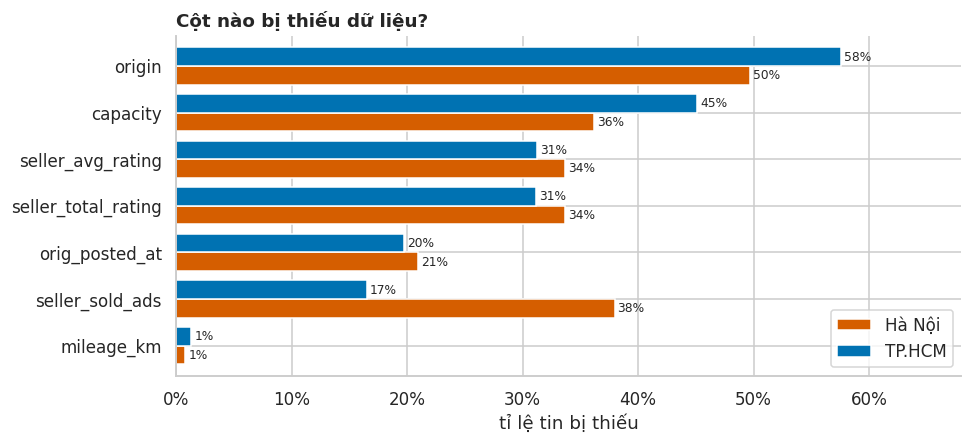

**Hình 1.** 13 cột có ô thiếu (hình vẽ 7 cột thiếu từ 0.5% trở lên). Thiếu nhiều nhất là `origin` (56.1%) và `capacity` (43.4%, gồm 132 giá trị ẩn), hai ô không bắt buộc khi đăng tin. Hai thành phố chỉ chênh nhau rõ ở `seller_sold_ads` (17% so với 38%).

In [7]:
HIDDEN_NA = {"capacity": ["Không biết rõ", "mã 0"]}
na_view = raw.copy()
for col, values in HIDDEN_NA.items():
    na_view[col] = na_view[col].where(~na_view[col].isin(values))

miss = na_view.drop(columns="city").isna().groupby(na_view["city"]).mean().T
n_missing_any = int((miss.max(axis=1) > 0).sum())
miss = miss[miss.max(axis=1) >= 0.005].sort_values("TP.HCM")
fig, ax = plt.subplots(figsize=(9, 4.2))
miss.plot.barh(ax=ax, color=CITY_COLORS, width=0.8)
for c in ax.containers:
    ax.bar_label(c, labels=[pct(v.get_width(), 0) for v in c], fontsize=8, padding=2)
ax.set(xlabel="tỉ lệ tin bị thiếu", ylabel="", title="Cột nào bị thiếu dữ liệu?")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_xlim(0, 0.68)
ax.legend(title="")

hidden = int(raw["capacity"].isin(HIDDEN_NA["capacity"]).sum())
gap = (miss["Hà Nội"] - miss["TP.HCM"]).abs()
show_fig(fig, "missing",
    f"{n_missing_any} cột có ô thiếu (hình vẽ {len(miss)} cột thiếu từ 0.5% trở lên). Thiếu nhiều nhất là `origin` "
    f"({pct(na_view['origin'].isna().mean())}) và `capacity` ({pct(na_view['capacity'].isna().mean())}, gồm {hidden} "
    f"giá trị ẩn), hai ô không bắt buộc khi đăng tin. Hai thành phố chỉ chênh nhau rõ ở `{gap.idxmax()}` "
    f"({pct(miss.loc[gap.idxmax(), 'TP.HCM'], 0)} so với {pct(miss.loc[gap.idxmax(), 'Hà Nội'], 0)}).")

- **Nhận xét:** không cột feature nào thiếu quá 60%. `origin` và `capacity` thiếu nhiều nhưng một phần thông tin có
  thể lấy lại từ tiêu đề (ví dụ "Vision 110cc", mục 5.2).
- **Quyết định:**
  - Cột phân loại bị thiếu được điền bằng nhóm riêng `không rõ`, vì "người bán không khai" cũng là thông tin.
  - Cột số bị thiếu được điền bằng median của train, kèm cột cờ cho biết ô đó vốn bị thiếu (mục 5.3).
  - `orig_posted_at` là metadata, không dùng làm feature.

### 3.2 Cột không mang thông tin

Một cột chỉ có một giá trị cho mọi dòng không giúp mô hình phân biệt các xe. Tọa độ cũng cần kiểm tra: nếu nhiều tin
chung một tọa độ thì đó là tọa độ của phường, không phải vị trí thật của chiếc xe.

In [8]:
const_cols = [c for c in raw.columns if raw[c].nunique() == 1]
display(pd.DataFrame({c: {"giá trị": raw[c].dropna().iloc[0], "số ô có giá trị đó": int(raw[c].notna().sum()),
                          "số ô thiếu": int(raw[c].isna().sum())} for c in const_cols}).T)

n_coords = len(raw[["latitude", "longitude"]].drop_duplicates())
print(f"Số cặp tọa độ khác nhau: {num(n_coords)} cho {num(n_rows)} tin; số phường/xã: {raw['ward'].nunique()}")

,giá trị,số ô có giá trị đó,số ô thiếu
is_price_not_valid,False,19718,0
has_video,True,19718,0
inspected,2.0,19717.0,1.0


Số cặp tọa độ khác nhau: 1 243 cho 19 718 tin; số phường/xã: 428


- **Nhận xét:**
  - `is_price_not_valid` và `has_video` chỉ có một giá trị cho mọi tin; `inspected` cũng vậy, trừ 1 ô thiếu.
  - Tọa độ chỉ có khoảng 1 200 cặp khác nhau, gần bằng số phường, nên đây là tọa độ đại diện của phường.
- **Quyết định:**
  - Bỏ ba cột hằng.
  - Bỏ `latitude`, `longitude` và `ward`. Vị trí được biểu diễn bằng `city` và `district`; phường có 428 mức, quá chi tiết so với số tin.

### 3.3 Giá và năm đăng ký không hợp lệ

Bốn loại tin không phải tin bán xe thật hoặc có giá trị không thể xảy ra:

- **Giá tượng trưng hoặc giá rác:** giá dưới 2 triệu (xe máy cũ rẻ nhất trên trang khoảng 2-3 triệu) hoặc trên 2 tỷ.
- **Tin cần mua:** tiêu đề như "thu mua xe cũ", "cần mua"; đây là quảng cáo của người mua, giá không phải giá xe.
- **Năm đăng ký không thể:** năm trước 1980 hoặc sau năm đăng tin.

In [9]:
WANTED = r"^\s*(?:mua|thu mua|cần mua|cần tìm)\b|\bthu mua\b|\bcần mua\b"
PRICE_RANGE = (2e6, 2e9)
REG_YEAR_MIN = 1980

subject = raw["subject"].str.lower()
problems = {
    "giá thiếu": raw[TARGET].isna(),
    "giá < 2 triệu": raw[TARGET] < PRICE_RANGE[0],
    "giá > 2 tỷ": raw[TARGET] > PRICE_RANGE[1],
    "tin cần mua / thu mua": subject.str.contains(WANTED),
    "năm đăng ký < 1980 hoặc > năm đăng tin": (raw["reg_year"] < REG_YEAR_MIN) | (raw["reg_year"] > raw["posted_at"].dt.year),
}
display(pd.DataFrame({"số tin": {k: int(v.sum()) for k, v in problems.items()}}))
with pd.option_context("display.max_colwidth", 70):
    display(raw.nlargest(4, TARGET)[["subject", "brand", "model", TARGET]])
    display(raw.loc[problems["tin cần mua / thu mua"], ["subject", "brand", "model", TARGET]].head(4))
display(raw.loc[raw["reg_year"].between(1978, 1990), "reg_year"].value_counts().sort_index().rename("số tin").to_frame().T)

,số tin
giá thiếu,1
giá < 2 triệu,42
giá > 2 tỷ,2
tin cần mua / thu mua,32
năm đăng ký < 1980 hoặc > năm đăng tin,3


,subject,brand,model,price_vnd
11230,MUA XE CŨ TẬN NHÀ GIÁ CAO 24/24. KO NGHẠI XA. LH,Yamaha,Sirius,8.888888e+09
1685,Honda Cub cánh nén Xanh,Honda,Cub,6.500000e+09
9601,___CVO Độc Nhất VietNam___,Harley Davidson,CVO,1.495000e+09
9841,___CVO 2021___Độc Nhất VietNam,Harley Davidson,CVO,1.490000e+09


,subject,brand,model,price_vnd
1430,Mua xe máy cũ GIÁ CAO HƠN THỊ TRƯỜNG,Piaggio,Vespa,30000000.0
3080,Mua xe Cũ Các Dòng xe Tận Nhà 24/24,Yamaha,Exciter,88800000.0
3445,MUA XE MÁY CŨ GIÁ CAO HƠN THỊ TRƯỜNG,Honda,Air Blade,35500000.0
3499,❤️CỬA HÀNG THU MUA XE MÁY ĐIỆN CŨ,VinFast,Evo200,38999000.0


reg_year,1980,1981,1982,1984,1985,1986,1987,1988,1989,1990
số tin,54,22,11,16,3,15,2,3,3,12


- **Nhận xét:**
  - Hai tin trên 2 tỷ là một tin thu mua xe đặt giá 8.9 tỷ và một chiếc Cub giá 6.5 tỷ. Hai tin đắt tiếp theo là Harley-Davidson CVO khoảng 1.5 tỷ, giá thật của dòng xe này, nên ngưỡng trên được đặt ở 2 tỷ chứ không phải 1 tỷ.
  - Tin cần mua thường do cửa hàng thu mua xe cũ đăng, gắn đại một hãng và một dòng xe.
  - 54 tin ghi đúng năm 1980, nhiều hơn hẳn các năm 1981-1989. Đây nhiều khả năng là lựa chọn "1980 trở về trước" của trang, nên vẫn giữ lại.
- **Quyết định:** bỏ các tin trong bảng trên (mục 3.6).

### 3.4 Số km "ảo"

Số km là ô người bán tự gõ. Nếu nhiều người gõ cùng một con số "dễ gõ" thì con số đó không phản ánh số km thật.
Hình dưới đếm 15 giá trị `mileage_km` xuất hiện nhiều nhất trong tin xe **đã sử dụng**.

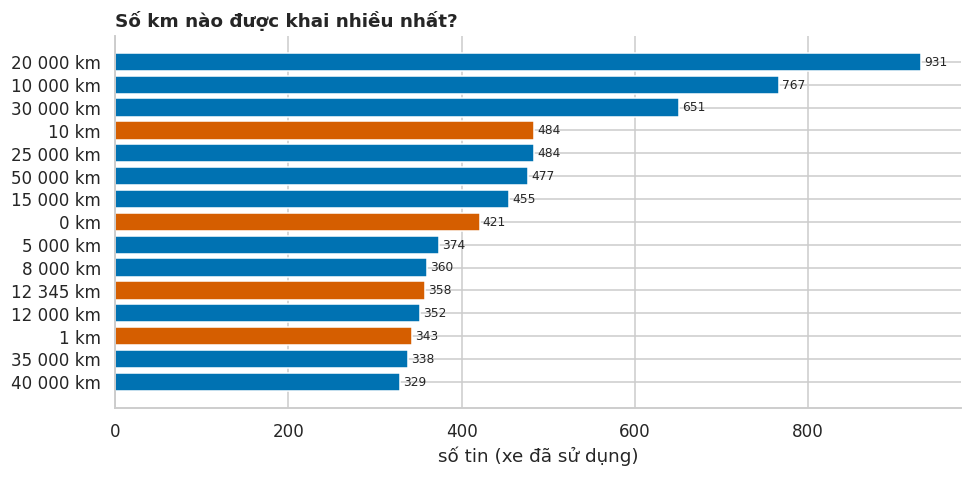

**Hình 2.** Màu cam là số km không thể có ở xe đã dùng: **12 345 km** xuất hiện 358 lần, nhiều hơn cả 12 000 km (352 lần). Tổng cộng 2 093 tin (10.8%) khai số km ảo và 168 tin khai trên 500 000 km. Các giá trị này được coi là **thiếu**, tin vẫn được giữ.

In [10]:
FAKE_KM = [0, 1, 10, 100, 1000, 12345, 123456, 99999, 111111, 999999]
MAX_KM = 500_000

used = raw[raw["condition"] == "Đã sử dụng"]
top_km = used["mileage_km"].value_counts().head(15)
is_fake = top_km.index.isin(FAKE_KM)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([f"{num(v)} km" for v in top_km.index[::-1]], top_km.values[::-1],
        color=[ACCENT if f else MAIN for f in is_fake[::-1]])
ax.bar_label(ax.containers[0], fontsize=8, padding=2)
ax.set(xlabel="số tin (xe đã sử dụng)", title="Số km nào được khai nhiều nhất?")

n_fake = int(used["mileage_km"].isin(FAKE_KM).sum())
n_big = int((used["mileage_km"] > MAX_KM).sum())
n_12345 = int((used["mileage_km"] == 12345).sum())
n_12000 = int((used["mileage_km"] == 12000).sum())
show_fig(fig, "fake_km",
    f"Màu cam là số km không thể có ở xe đã dùng: **12 345 km** xuất hiện {n_12345} lần, nhiều hơn cả 12 000 km "
    f"({n_12000} lần). Tổng cộng {num(n_fake)} tin ({pct(n_fake / len(used))}) khai số km ảo và {n_big} tin khai trên "
    f"{num(MAX_KM)} km. Các giá trị này được coi là **thiếu**, tin vẫn được giữ.")

### 3.5 Tin đăng lại

Người bán có thể đăng cùng một chiếc xe nhiều lần với `list_id` khác nhau. Nếu hai bản của cùng một chiếc xe rơi vào
train và test, mô hình sẽ được chấm trên chiếc xe nó đã thấy, làm điểm test cao hơn thực tế. Hai tin được coi là
trùng khi giống nhau ở cả thành phố, quận, hãng, dòng xe, năm đăng ký, số km và giá.

In [11]:
REPOST_KEY = ["city", "district", "brand", "model", "reg_year", "mileage_km", TARGET]
dup = raw.duplicated(REPOST_KEY, keep="first")
print(f"list_id trùng: {raw['list_id'].duplicated().sum()} | tin đăng lại: {num(dup.sum())} ({pct(dup.mean())})")
example_key = raw.loc[dup & raw["mileage_km"].notna(), REPOST_KEY].iloc[0]
with pd.option_context("display.max_colwidth", 60):
    display(raw[(raw[REPOST_KEY] == example_key).all(axis=1)][["list_id", "posted_at", "subject"] + REPOST_KEY[1:]])

list_id trùng: 0 | tin đăng lại: 518 (2.6%)


,list_id,posted_at,subject,district,brand,model,reg_year,mileage_km,price_vnd
309,135118562,2026-11-07 18:27:27,Kymco Candy Hermosa 2020 Hồng,Quận 4,Kymco,Hermosa,2020,10000.0,11900000.0
368,135408513,2026-10-22 22:20:13,Kymco Candy Hermosa 2020 50cc bstp,Quận 4,Kymco,Hermosa,2020,10000.0,11900000.0


### 3.6 Tổng kết: vấn đề và cách xử lý

| Vấn đề | Cách xử lý | Khi nào |
|---|---|---|
| `capacity` có giá trị ẩn *Không biết rõ*, *mã 0* | đổi thành thiếu | trước khi chia (luật cố định) |
| Ba cột hằng; tọa độ và phường quá chi tiết | bỏ cột | trước khi chia |
| Giá ngoài 2 triệu - 2 tỷ, tin cần mua, năm đăng ký không thể | bỏ tin | trước khi chia |
| Tin đăng lại | giữ bản đầu tiên | trước khi chia, để một chiếc xe không nằm ở hai tập |
| Dòng xe hiếm và nhóm "Dòng khác" | ngoài phạm vi bài toán | trước khi chia (mục 3.7) |
| Số km ảo hoặc trên 500 000 km | coi là thiếu, giữ tin | trong bước tạo feature (mục 5.2) |
| Giá thấp vô lý so với dòng xe (tiền cọc, trả trước) | bỏ tin | sau khi chia: ngưỡng học từ train, áp dụng cho cả ba tập (mục 5.1) |
| Cột thiếu dữ liệu | điền bằng thống kê của train | trong pipeline (mục 5.3) |

### 3.7 Phạm vi bài toán: các dòng xe phổ biến

Dữ liệu có hơn 400 tổ hợp hãng + dòng xe, nhưng phần lớn chỉ có vài tin. Với một dòng xe chỉ có 3-5 tin, mô hình không
có đủ ví dụ để học giá của dòng đó, và điểm trên test của dòng đó cũng không đáng tin. Vì vậy bài toán được giới hạn
vào các **dòng xe phổ biến**:

- một tổ hợp hãng + dòng xe là phổ biến nếu có **ít nhất 40 tin** sau khi làm sạch. Khi chia 70 / 15 / 15, mỗi dòng có
  khoảng 28 tin để học và khoảng 6 tin để chấm;
- nhóm `Dòng khác` luôn nằm ngoài phạm vi, vì đó là nhóm gộp của nhiều loại xe không rõ tên.

Luật chỉ dựa trên số tin của mỗi dòng xe, không dựa trên giá của từng tin. Mô hình ở mục 8 từ chối dự đoán xe ngoài
phạm vi. Ngưỡng 40 tin được chọn sau khi thử vài phạm vi khác nhau (xem hạn chế ở mục 9.3).

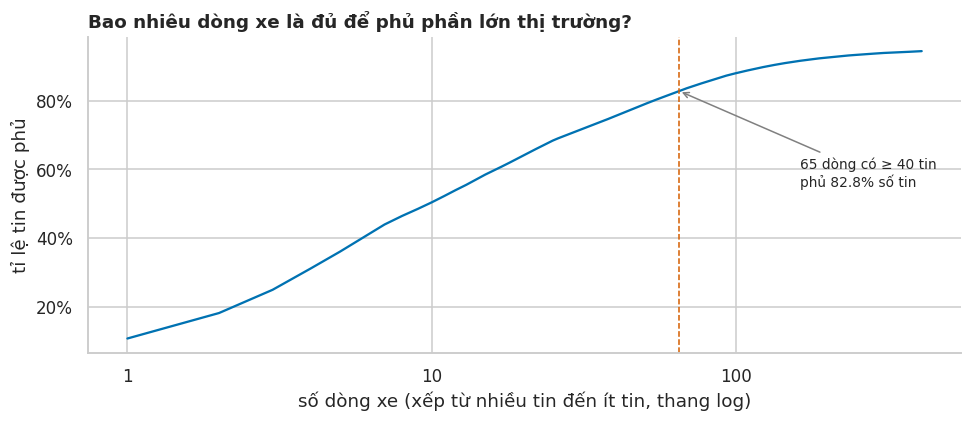

**Hình 3.** **65 dòng xe có từ 40 tin** chiếm 82.8% số tin. 343 dòng còn lại chỉ chiếm 11.6% (trung bình 6.5 tin mỗi dòng), nhóm `Dòng khác` chiếm 5.6%.

In [12]:
DROP_COLS = const_cols + ["latitude", "longitude", "ward"]

def apply_rules(df):
    steps = {"dữ liệu thô": len(df)}
    df = df.drop(columns=DROP_COLS)
    for col, values in HIDDEN_NA.items():
        df[col] = df[col].where(~df[col].isin(values))
    ok = (df[TARGET].between(*PRICE_RANGE) & ~df["subject"].str.lower().str.contains(WANTED)
          & df["reg_year"].between(REG_YEAR_MIN, df["posted_at"].dt.year))
    df = df[ok]
    steps["bỏ giá rác, tin cần mua, năm không thể"] = len(df)
    df = df.drop_duplicates(REPOST_KEY)
    steps["bỏ tin đăng lại"] = len(df)
    return df.reset_index(drop=True), pd.Series(steps, name="số tin")

MIN_MODEL_ADS_SCOPE = 40
clean, funnel = apply_rules(raw)
brand_model = clean["brand"] + " | " + clean["model"]
model_counts = brand_model.value_counts()
is_other = model_counts.index.str.endswith("Dòng khác")
POPULAR = model_counts.index[(model_counts >= MIN_MODEL_ADS_SCOPE) & ~is_other]

ranked = model_counts[~is_other]
coverage = ranked.cumsum() / len(clean)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(ranked) + 1), coverage.values, color=MAIN)
ax.axvline(len(POPULAR), color=ACCENT, ls="--", lw=1)
ax.annotate(f"{len(POPULAR)} dòng có ≥ {MIN_MODEL_ADS_SCOPE} tin\nphủ {pct(coverage.iloc[len(POPULAR) - 1])} số tin",
            xy=(len(POPULAR), coverage.iloc[len(POPULAR) - 1]), xytext=(len(POPULAR) * 2.5, 0.55),
            arrowprops={"arrowstyle": "->", "color": "grey"}, fontsize=9)
ax.set(xscale="log", xlabel="số dòng xe (xếp từ nhiều tin đến ít tin, thang log)", ylabel="tỉ lệ tin được phủ",
       title="Bao nhiêu dòng xe là đủ để phủ phần lớn thị trường?")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _pos: f"{v:g}"))

rare = ranked[ranked < MIN_MODEL_ADS_SCOPE]
show_fig(fig, "scope",
    f"**{len(POPULAR)} dòng xe có từ {MIN_MODEL_ADS_SCOPE} tin** chiếm {pct(model_counts[POPULAR].sum() / len(clean))} "
    f"số tin. {len(rare)} dòng còn lại chỉ chiếm {pct(rare.sum() / len(clean))} (trung bình {rare.mean():.1f} tin mỗi "
    f"dòng), nhóm `Dòng khác` chiếm {pct(model_counts[is_other].sum() / len(clean))}.")

### 3.8 Áp dụng luật làm sạch và chia train / validation / test

Tập dữ liệu được chia **trước khi phân tích khám phá**, để mọi quyết định ở mục 4 và 5 chỉ dựa trên train. Tỉ lệ
70 / 15 / 15, phân tầng theo thành phố và 10 khoảng giá, để ba tập có cùng tỉ lệ TP.HCM / Hà Nội và cùng phân phối giá.

In [13]:
clean = clean[brand_model.isin(POPULAR)].reset_index(drop=True)
funnel["giữ dòng xe phổ biến"] = len(clean)
display(funnel.to_frame().assign(bị_bỏ=lambda t: -t["số tin"].diff().fillna(0).astype(int)))

strata = clean["city"] + "_" + pd.qcut(np.log10(clean[TARGET]), 10, labels=False).astype(str)
train_df, rest = train_test_split(clean, test_size=0.30, stratify=strata, random_state=SEED)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=strata.loc[rest.index], random_state=SEED)
SPLITS = {"train": train_df, "val": val_df, "test": test_df}
display(pd.DataFrame({name: {"số tin": len(d), "tỉ lệ Hà Nội": pct(d["city"].eq("Hà Nội").mean()),
                             "giá median (triệu)": d[TARGET].median() / 1e6} for name, d in SPLITS.items()}).T)

,số tin,bị_bỏ
dữ liệu thô,19718,0
"bỏ giá rác, tin cần mua, năm không thể",19644,74
bỏ tin đăng lại,19127,517
giữ dòng xe phổ biến,15841,3286


,số tin,tỉ lệ Hà Nội,giá median (triệu)
train,11088,19.1%,19.0
val,2376,19.1%,19.0
test,2377,19.0%,19.0


## 4. Phân tích khám phá (EDA)

Phân tích khám phá chỉ dùng **tập train**, để mọi hiểu biết về dữ liệu không đến từ tập validation hay test.

### 4.1 Giá xe phân bố thế nào?

Nếu target lệch mạnh, lỗi của vài chiếc xe rất đắt sẽ chi phối hàm mất mát, và cần đổi thang đo.

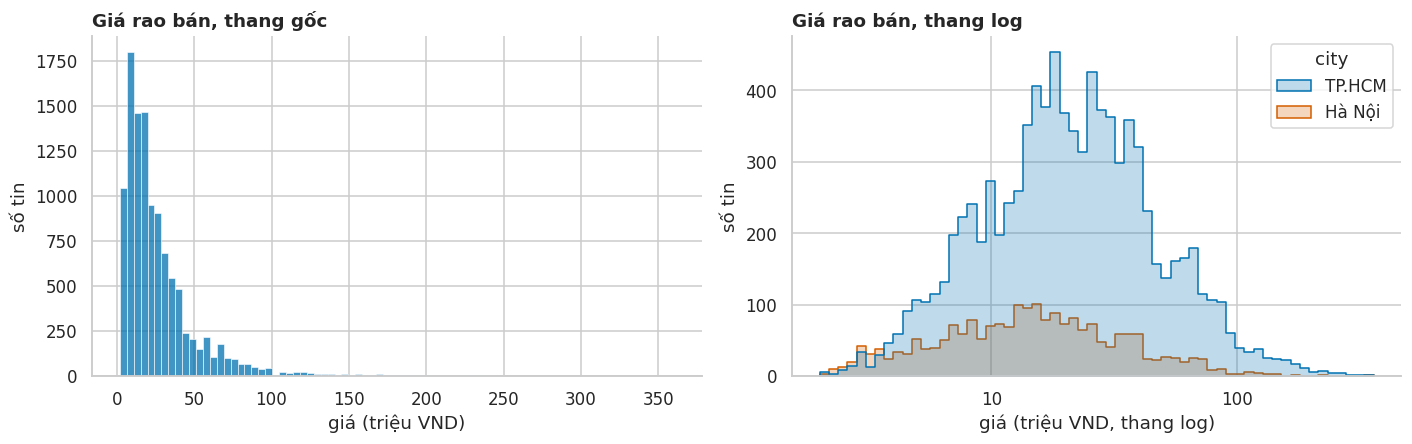

**Hình 4.** Giá lệch phải mạnh (skew 3.3) nhưng gần đối xứng trên thang log (skew 0.03). Giá median: TP.HCM 20.5 triệu, Hà Nội 14.5 triệu. Mô hình học trên **log10(giá)** để sai 10% ở xe rẻ và ở xe đắt được tính như nhau.

In [14]:
eda = train_df.copy()
eda["log_price"] = np.log10(eda[TARGET])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(eda[TARGET] / 1e6, bins=80, color=MAIN, ax=axes[0])
axes[0].set(title="Giá rao bán, thang gốc", xlabel="giá (triệu VND)", ylabel="số tin")
sns.histplot(data=eda, x=TARGET, hue="city", bins=60, log_scale=True, element="step", palette=CITY_COLORS, ax=axes[1])
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(trieu))
axes[1].set(title="Giá rao bán, thang log", xlabel="giá (triệu VND, thang log)", ylabel="số tin")

med = eda.groupby("city")[TARGET].median()
show_fig(fig, "target",
    f"Giá lệch phải mạnh (skew {eda[TARGET].skew():.1f}) nhưng gần đối xứng trên thang log (skew "
    f"{eda['log_price'].skew():.2f}). Giá median: TP.HCM {med['TP.HCM'] / 1e6:.1f} triệu, Hà Nội "
    f"{med['Hà Nội'] / 1e6:.1f} triệu. Mô hình học trên **log10(giá)** để sai 10% ở xe rẻ và ở xe đắt được tính như nhau.")

### 4.2 Giá phụ thuộc vào dòng xe ra sao?

Dòng xe là thông tin quan trọng nhất về một chiếc xe. Số mức và độ chênh giá giữa các dòng quyết định cách mã hóa cột
này.

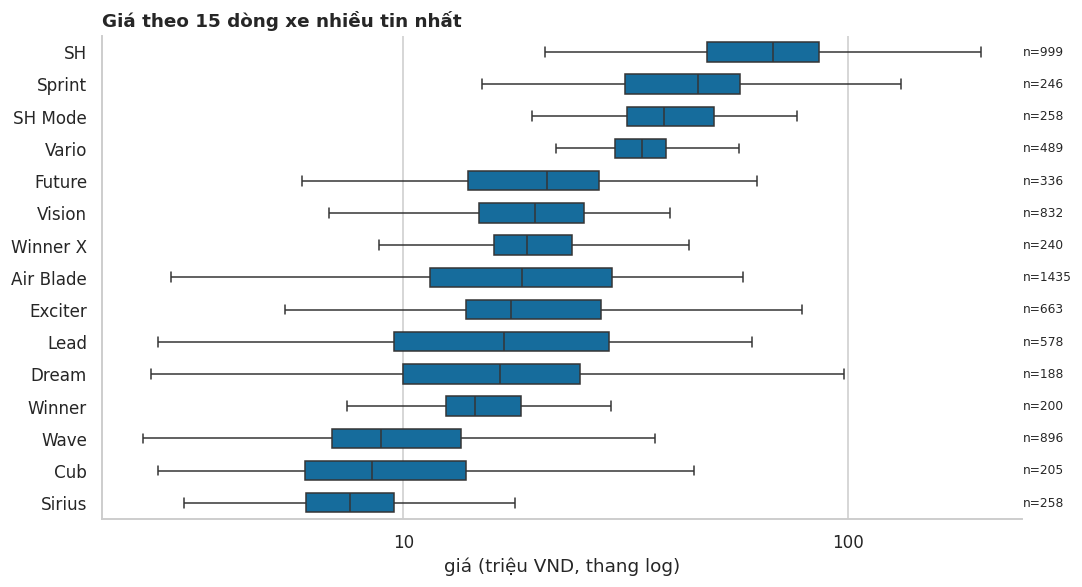

**Hình 5.** Median của SH (68 triệu) gấp 9 lần Sirius (7.6 triệu): dòng xe gần như quyết định mức giá. Train có 65 tổ hợp hãng + dòng xe và 50 quận/huyện, bằng hoặc vượt ngưỡng 50 mức của bài EDA mẫu, nên các cột này được mã hóa bằng **target encoding** kèm one-hot (mục 5.4).

In [15]:
counts = eda["model"].value_counts()
top_models = counts.index[:15]
order = eda[eda["model"].isin(top_models)].groupby("model")[TARGET].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=eda[eda["model"].isin(top_models)], y="model", x=TARGET, order=order, color=MAIN,
            showfliers=False, width=0.6, log_scale=True, ax=ax)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(trieu))
for i, m in enumerate(order):
    ax.text(1.0, i, f"n={counts[m]}", transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize=8)
ax.set(xlabel="giá (triệu VND, thang log)", ylabel="", title="Giá theo 15 dòng xe nhiều tin nhất")

med_model = eda.groupby("model")[TARGET].median()
n_bm = (eda["brand"] + " | " + eda["model"]).nunique()
show_fig(fig, "price_by_model",
    f"Median của {order[0]} ({med_model[order[0]] / 1e6:.0f} triệu) gấp {med_model[order[0]] / med_model[order[-1]]:.0f} "
    f"lần {order[-1]} ({med_model[order[-1]] / 1e6:.1f} triệu): dòng xe gần như quyết định mức giá. Train có {n_bm} tổ "
    f"hợp hãng + dòng xe và {eda['district'].nunique()} quận/huyện, bằng hoặc vượt ngưỡng 50 mức của bài EDA mẫu, nên các cột này "
    f"được mã hóa bằng **target encoding** kèm one-hot (mục 5.4).")

### 4.3 Xe mất giá bao nhiêu theo đời xe và số km?

Hai yếu tố mà người mua nào cũng hỏi là "xe đời nào" và "đi bao nhiêu km". Để không lẫn với khác biệt giữa các dòng
xe, đường mất giá được vẽ riêng cho 4 dòng xe nhiều tin nhất.

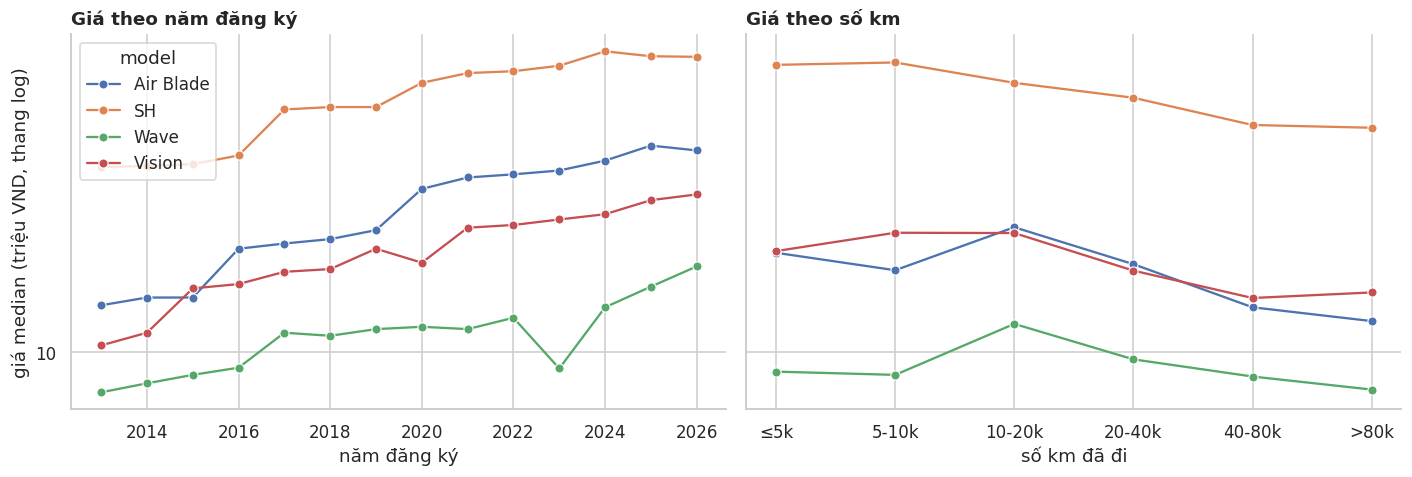

**Hình 6.** Mỗi năm đời xe cũ hơn, giá median giảm khoảng 9% với Air Blade, 7% với SH, 5% với Wave, 7% với Vision. Xe đi trên 80 000 km còn 61%, 64%, 88%, 74% giá xe đi dưới 5 000 km (cùng thứ tự), giảm không đều vì số km đi cùng đời xe. Mục 5.2 thêm **tuổi xe** và **km mỗi năm** để tách hai ảnh hưởng.

In [16]:
top4 = counts.index[:4]
sub4 = eda[eda["model"].isin(top4)].copy()
real_km = sub4["mileage_km"].where(~sub4["mileage_km"].isin(FAKE_KM) & (sub4["mileage_km"] <= MAX_KM))
sub4["km_band"] = pd.cut(real_km, [0, 5e3, 1e4, 2e4, 4e4, 8e4, 5e5],
                         labels=["≤5k", "5-10k", "10-20k", "20-40k", "40-80k", ">80k"])
by_year = sub4[sub4["reg_year"] >= 2013].groupby(["model", "reg_year"])[TARGET].agg(["median", "size"]).reset_index()
by_year = by_year[by_year["size"] >= 10]
by_km = sub4.groupby(["model", "km_band"], observed=True)[TARGET].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sns.lineplot(data=by_year, x="reg_year", y="median", hue="model", hue_order=top4, marker="o", ax=axes[0])
axes[0].set(yscale="log", xlabel="năm đăng ký", ylabel="giá median (triệu VND, thang log)",
            title="Giá theo năm đăng ký")
sns.lineplot(data=by_km, x="km_band", y=TARGET, hue="model", hue_order=top4, marker="o", legend=False, ax=axes[1])
axes[1].set(xlabel="số km đã đi", title="Giá theo số km")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(trieu))
axes[0].yaxis.set_minor_formatter(mticker.NullFormatter())

slope = {m: np.polyfit(g["reg_year"], np.log10(g["median"]), 1)[0] for m, g in by_year.groupby("model")}
loss = {m: 1 - 10 ** -s for m, s in slope.items()}
km_drop = by_km.pivot(index="km_band", columns="model", values=TARGET)
km_ratio = (km_drop.loc[">80k"] / km_drop.loc["≤5k"]).reindex(top4)
show_fig(fig, "depreciation",
    "Mỗi năm đời xe cũ hơn, giá median giảm khoảng " + ", ".join(f"{pct(loss[m], 0)} với {m}" for m in top4)
    + ". Xe đi trên 80 000 km còn " + ", ".join(f"{pct(km_ratio[m], 0)}" for m in top4)
    + " giá xe đi dưới 5 000 km (cùng thứ tự), giảm không đều vì số km đi cùng đời xe. Mục 5.2 thêm **tuổi xe** và "
    "**km mỗi năm** để tách hai ảnh hưởng.")

Đường mất giá chỉ vẽ từ năm 2013. SH đăng ký năm 2010-2012 phần lớn là bản nhập khẩu từ Ý, giá cao hơn bản lắp ráp
trong nước những năm sau, nên nếu tính cả các năm này thì SH trông như "không mất giá". Đây cũng là lý do mục 5.2 tách
dòng xe theo dung tích và đưa từ khóa "nhập khẩu" trong tiêu đề vào làm feature.

### 4.4 Cùng một chiếc xe, Hà Nội có rẻ hơn TP.HCM không?

Ở mục 4.1, giá median ở Hà Nội thấp hơn TP.HCM. Khác biệt đó có thể chỉ vì hai nơi bán những dòng xe khác nhau. Để
so sánh công bằng, mỗi tin được chia cho **giá median của tin TP.HCM cùng dòng xe và cùng năm đăng ký** (chỉ dùng các
nhóm có ít nhất 5 tin TP.HCM). Tỉ số 1 nghĩa là rao bằng giá TP.HCM.

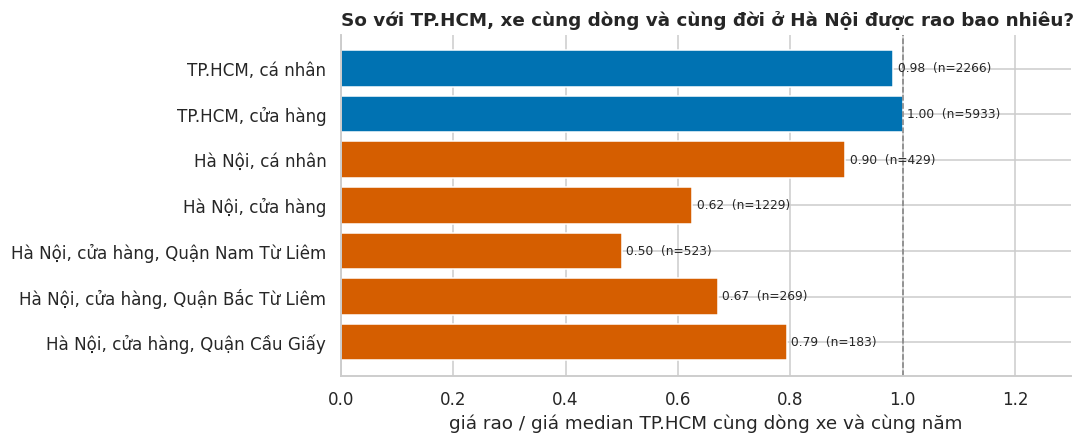

**Hình 7.** Ở Hà Nội, người bán cá nhân rao bằng 0.90 lần giá TP.HCM, nhưng **cửa hàng** chỉ 0.62 lần, thấp nhất ở Quận Nam Từ Liêm (0.50 lần; quận này chiếm 32% số tin Hà Nội). Chênh lệch giữa hai thành phố chủ yếu đến từ nhóm cửa hàng này, có thể là giá mồi (chưa kiểm chứng được), nên mô hình giữ `city`, `district` và `seller_is_shop`.

In [17]:
ref = eda[eda["city"] == "TP.HCM"].groupby(["model", "reg_year"])[TARGET].agg(["median", "size"])
ref = ref.loc[ref["size"] >= 5, "median"].rename("hcm_median")
cmp = eda.join(ref, on=["model", "reg_year"], how="inner")
cmp["ratio"] = cmp[TARGET] / cmp["hcm_median"]
cmp["seller"] = cmp["seller_is_shop"].map({True: "cửa hàng", False: "cá nhân"})
cmp["group"] = cmp["city"] + ", " + cmp["seller"]
hn_store = cmp[(cmp["city"] == "Hà Nội") & cmp["seller_is_shop"]]
top_d = hn_store["district"].value_counts().index[:3]
groups = pd.concat([cmp.groupby("group")["ratio"].agg(["median", "size"]),
                    hn_store[hn_store["district"].isin(top_d)].groupby("district")["ratio"].agg(["median", "size"])
                    .rename(index=lambda d: f"Hà Nội, cửa hàng, {d}")])
groups = groups.loc[["TP.HCM, cá nhân", "TP.HCM, cửa hàng", "Hà Nội, cá nhân", "Hà Nội, cửa hàng"]
                    + [f"Hà Nội, cửa hàng, {d}" for d in top_d]]

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [CITY_COLORS["TP.HCM"] if g.startswith("TP.HCM") else CITY_COLORS["Hà Nội"] for g in groups.index]
ax.barh(groups.index[::-1], groups["median"][::-1], color=colors[::-1])
ax.bar_label(ax.containers[0], labels=[f"{m:.2f}  (n={n})" for m, n in zip(groups["median"][::-1], groups["size"][::-1])],
             fontsize=8, padding=3)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set(xlim=(0, 1.3), xlabel="giá rao / giá median TP.HCM cùng dòng xe và cùng năm",
       title="So với TP.HCM, xe cùng dòng và cùng đời ở Hà Nội được rao bao nhiêu?")

share_d = eda.loc[eda["city"] == "Hà Nội", "district"].value_counts(normalize=True)
show_fig(fig, "hanoi_vs_hcm",
    f"Ở Hà Nội, người bán cá nhân rao bằng {groups.loc['Hà Nội, cá nhân', 'median']:.2f} lần giá TP.HCM, nhưng "
    f"**cửa hàng** chỉ {groups.loc['Hà Nội, cửa hàng', 'median']:.2f} lần, thấp nhất ở {top_d[0]} "
    f"({groups.loc[f'Hà Nội, cửa hàng, {top_d[0]}', 'median']:.2f} lần; quận này chiếm {pct(share_d[top_d[0]], 0)} số tin "
    f"Hà Nội). Chênh lệch giữa hai thành phố chủ yếu đến từ nhóm cửa hàng này, có thể là giá mồi (chưa kiểm chứng "
    f"được), nên mô hình giữ `city`, `district` và `seller_is_shop`.")

### 4.5 Các cột số: phân phối và tương quan

Thống kê mô tả và độ lệch (skew) cho biết cột nào cần đổi thang đo. Tương quan Spearman (hợp với cột lệch và quan hệ
không tuyến tính) cho biết cột nào liên quan đến giá và cặp cột nào gần như trùng thông tin.

In [18]:
num_summary = eda[raw_num_cols].describe().T[["count", "mean", "50%", "max"]]
num_summary["skew"] = eda[raw_num_cols].skew()
corr = eda[raw_num_cols + ["log_price"]].corr(method="spearman")
num_summary["spearman_log_price"] = corr.loc[raw_num_cols, "log_price"]
display(num_summary.sort_values("spearman_log_price", key=abs, ascending=False).round(2))

pairs = corr.loc[raw_num_cols, raw_num_cols].where(np.tril(np.ones((len(raw_num_cols),) * 2, dtype=bool), k=-1)).stack()
a, b = pairs.abs().idxmax()
print(f"Cặp cột số tương quan mạnh nhất: {a} và {b} ({pairs[(a, b)]:+.2f})")

,count,mean,50%,max,skew,spearman_log_price
reg_year,11088.0,2016.68,2018.0,2026.0,-1.40,0.44
number_of_images,11088.0,7.31,7.0,56.0,1.34,0.32
mileage_km,11005.0,35168.65,18000.0,1000000.0,7.56,-0.15
seller_total_rating,7636.0,29.03,9.0,336.0,3.57,0.13
seller_live_ads,11088.0,40.00,13.0,440.0,3.73,0.12
seller_sold_ads,8828.0,544.06,59.0,13405.0,5.97,0.07
seller_avg_rating,7633.0,4.48,4.7,5.0,-2.37,0.04


Cặp cột số tương quan mạnh nhất: seller_total_rating và seller_live_ads (+0.52)


- **Nhận xét:**
  - `reg_year` tương quan với giá mạnh nhất (+0.44), nhưng không cột số nào vượt 0.5: phần lớn khác biệt về giá nằm ở dòng xe (mục 4.2).
  - Các cột đếm của người bán và `mileage_km` lệch phải mạnh (skew 3.6-7.6), một phần vì các số km ảo rất lớn.
  - Cặp mạnh nhất là `seller_total_rating` và `seller_live_ads` (+0.52), chưa tới ngưỡng 0.7 của bài EDA mẫu.
- **Quyết định:** giữ mọi cột; lấy log số km sau khi bỏ số ảo; chuẩn hóa cột số bằng StandardScaler học trên train (mục 5.5).

### 4.6 Outlier

Outlier được đếm bằng quy tắc IQR (ngoài khoảng Q1 - 1.5 IQR đến Q3 + 1.5 IQR), trên thang gốc và thang log của giá.

In [19]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return {"cận dưới": lo, "cận trên": hi, "số outlier": int(((s < lo) | (s > hi)).sum()),
            "% outlier": round(100 * ((s < lo) | (s > hi)).mean(), 1)}

outliers = pd.DataFrame({c: iqr_outliers(eda[c]) for c in raw_num_cols + [TARGET, "log_price"]}).T
outliers.round(2)

,cận dưới,cận trên,số outlier,% outlier
reg_year,2001.00,2033.00,261.0,2.4
mileage_km,-36985.00,76591.00,790.0,7.2
number_of_images,-1.00,15.00,526.0,4.7
seller_live_ads,-56.50,99.50,908.0,8.2
seller_sold_ads,-448.00,768.00,1218.0,13.8
seller_avg_rating,3.25,6.05,539.0,7.1
seller_total_rating,-28.50,55.50,944.0,12.4
price_vnd,-23250000.00,67550000.00,765.0,6.9
log_price,6.30,8.26,34.0,0.3


- **Nhận xét:**
  - Theo IQR, 6.9% giá ở thang gốc là outlier. Đó là các xe phân khối lớn, đắt nhưng có thật.
  - Trên thang log, tỉ lệ outlier giảm còn 0.3%.
  - Outlier của `mileage_km` chủ yếu là các số km ảo ở mục 3.4.
- **Quyết định:**
  - Không bỏ thêm tin nào theo IQR, vì xe đắt là xe thật và mô hình cần học cả chúng.
  - Học trên log10(giá).
  - Số km ảo được coi là thiếu (mục 5.2).
  - Chỉ bỏ những tin có giá thấp vô lý so với dòng xe (mục 5.1).

### 4.7 Tổng kết EDA

| Phát hiện | Quyết định |
|---|---|
| Giá lệch phải mạnh, gần đối xứng trên thang log (mục 4.1) | Học trên log10(giá); báo cáo sai số theo % |
| Dòng xe quyết định mức giá; dòng xe và quận đều có từ 50 mức trở lên (mục 4.2) | Target encoding kèm one-hot cho `brand`, dòng xe, dòng xe + dung tích, `district` |
| Giá giảm đều theo năm đăng ký và số km, nhưng hai biến đi cùng nhau (mục 4.3) | Thêm `age`, `log_km`, `km_per_year` |
| Cửa hàng ở Hà Nội rao thấp hơn hẳn cùng dòng, cùng đời (mục 4.4) | Giữ `city`, `district`, `seller_is_shop`, `seller_live_ads` |
| Cột số lệch, khác thang đo (mục 4.5) | Điền median, StandardScaler, fit trên train |
| Outlier giá là xe đắt có thật (mục 4.6) | Không bỏ theo IQR |

## 5. Tiền xử lý dữ liệu

| Mục | Bước | Áp dụng cho |
|---|---|---|
| 5.1 | Bỏ tin giá thấp vô lý so với dòng xe | train / val / test (ngưỡng học từ train) |
| 5.2 | Tạo feature: tuổi xe, số km sạch, dung tích từ tiêu đề, từ khóa | train / val / test (luật theo từng dòng) |
| 5.3 | Điền giá trị thiếu | train / val / test (fit trên train, trong `Pipeline`) |
| 5.4 | Mã hóa cột phân loại: one-hot và target encoding | train / val / test (fit trên train, trong `Pipeline`) |
| 5.5 | Chuẩn hóa cột số bằng StandardScaler | train / val / test (fit trên train, trong `Pipeline`) |
| 5.6 | Kích thước cuối cùng của ba tập | |

**Nguyên tắc chống rò rỉ dữ liệu:** mọi thống kê học từ dữ liệu (ngưỡng giá, median để điền, mean/std để chuẩn hóa,
giá trung bình theo dòng xe) chỉ được fit trên train, rồi dùng lại cho validation và test.

### 5.1 Bỏ tin giá thấp vô lý

Một số tin rao giá thấp hơn nhiều so với dòng xe đó, ví dụ SH với giá vài triệu. Đây thường là tiền trả trước khi mua
trả góp hoặc tiền đặt cọc, không phải giá chiếc xe, nên chấm điểm mô hình trên các tin này không có ý nghĩa. Một tin
bị bỏ nếu giá dưới 15% giá median của dòng xe đó. Median được tính **trên train** và chỉ dùng cho dòng xe có ít nhất 20
tin trong train; ngưỡng học từ train này được áp dụng cho cả ba tập, giống mọi bước tiền xử lý khác. Khi dự đoán một xe
mới (mục 8) không cần luật này, vì luật chỉ lọc nhãn sai.

In [20]:
LOW_RATIO, MIN_MODEL_ADS = 0.15, 20

model_stats = train_df.groupby("model")[TARGET].agg(["median", "size"])
model_median = model_stats["median"].where(model_stats["size"] >= MIN_MODEL_ADS)

def drop_too_low(df):
    ref = df["model"].map(model_median)
    low = df[TARGET] < LOW_RATIO * ref
    return df[~low], df[low].assign(median_dong_xe=ref[low])

train_df, low_train = drop_too_low(train_df)
val_df, low_val = drop_too_low(val_df)
test_df, low_test = drop_too_low(test_df)
with pd.option_context("display.max_colwidth", 60):
    display(low_train[["subject", "model", "reg_year", TARGET, "median_dong_xe"]].head(6))
print(f"Số tin bị bỏ: train {len(low_train)}, val {len(low_val)}, test {len(low_test)} | "
      f"còn lại: train {num(len(train_df))}, val {num(len(val_df))}, test {num(len(test_df))}")

,subject,model,reg_year,price_vnd,median_dong_xe
13662,HONDA SCOOPY 50CC MÀU TRẮNG,Scoopy,2008,3500000.0,29800000.0
9045,Honda SH,SH,2025,10000000.0,68000000.0
9693,funeo,Vario,2019,4600000.0,34500000.0
9455,HONDA AIR BLADE 2018 XANH BẠC ĐEN,Air Blade,2018,2100000.0,18500000.0
5386,Honda Vision 2023 15000km xanh ngọc,Vision,2023,2520000.0,19800000.0
14355,ban xe scopi 50cc màu đỏ,Scoopy,2024,3000000.0,29800000.0


Số tin bị bỏ: train 12, val 2, test 3 | còn lại: train 11 076, val 2 374, test 2 374


### 5.2 Tạo feature

Các feature mới được tính theo từng dòng, không học gì từ dữ liệu, nên dùng chung một hàm cho cả ba tập và cho xe mới
ở mục 8:

- `age`: tuổi xe lúc đăng tin = năm đăng tin - năm đăng ký.
- `log_km`, `km_per_year`: số km (log) và số km mỗi năm tuổi, sau khi coi số km ảo ở mục 3.4 là thiếu. Xe mới
  (`condition = Mới`) được phép có 0 km.
- `cc_est`: dung tích ước lượng. Ưu tiên con số trong tiêu đề ("Vision 110", "SH 150i", "Exciter 155"), nếu không có
  thì lấy giữa khoảng của cột `capacity`.
- `kw_*`: tiêu đề có nhắc tới các đặc điểm làm tăng hay giảm giá không (ABS, smartkey, "zin", "lướt", biển số đẹp,
  hàng nhập, xe độ, trả góp).
- `brand_model`, `model_cc`: tổ hợp hãng + dòng xe và hãng + dòng xe + dung tích, vì cùng tên "SH" có bản 125, 150 và
  350 với giá rất khác nhau.

In [21]:
CC_PATTERN = r"(?<!\d)(50|70|100|110|115|125|135|150|155|160|175|200|250|300|350|400|500|600|650|750|800|900|1000|1200)(?:\s?cc|i|fi|r)?\b"
CAPACITY_CC = {"Dưới 50 cc": 50, "50 - 100 cc": 90, "100 - 175 cc": 130, "Trên 175 cc": 300}
KEYWORDS = {
    "abs": r"\babs\b", "smartkey": r"smart\s?key|khóa thông minh|khoá thông minh", "zin": r"\bzin\b|nguyên bản",
    "luot": r"lướt|như mới|mới tinh", "bien_dep": r"biển đẹp|biển vip|ngũ quý|tứ quý|biển 5 số",
    "nhap_khau": r"nhập khẩu|nhập ý|nhập thái|nhập indo|\bnhập\b", "do_xe": r"\bđộ\b|dọn kiểng|\bkiểng\b",
    "tra_gop": r"trả góp|\bgóp\b|trả trước",
}

def add_features(df):
    df = df.copy()
    title = df["subject"].fillna("").str.lower()
    df["age"] = df["posted_at"].dt.year - df["reg_year"]
    km = df["mileage_km"]
    fake = (km.isin(FAKE_KM) & (df["condition"] != "Mới")) | (km > MAX_KM)
    km = km.where(~fake)
    df["log_km"] = np.log1p(km)
    df["km_per_year"] = km / df["age"].clip(lower=1)
    title_cc = title.str.extract(CC_PATTERN, expand=False).astype(float)
    df["cc_est"] = title_cc.fillna(df["capacity"].map(CAPACITY_CC))
    for name, pattern in KEYWORDS.items():
        df[f"kw_{name}"] = title.str.contains(pattern).astype(int)
    df["brand_model"] = df["brand"] + " | " + df["model"]
    df["model_cc"] = df["brand_model"] + " | " + df["cc_est"].round(-1).astype("Int64").astype(str)
    df["seller_is_shop"] = df["seller_is_shop"].astype(int)
    return df

FEAT = {name: add_features(d) for name, d in {"train": train_df, "val": val_df, "test": test_df}.items()}
ft = FEAT["train"]
print(f"Số km bị coi là thiếu trong train: {pct(ft['log_km'].isna().mean())} "
      f"(cột gốc chỉ thiếu {pct(train_df['mileage_km'].isna().mean())})")
print(f"Lấy được dung tích từ tiêu đề: {pct(ft['subject'].str.lower().str.extract(CC_PATTERN, expand=False).notna().mean())} số tin; "
      f"cc_est còn thiếu {pct(ft['cc_est'].isna().mean())} (capacity gốc thiếu {pct(train_df['capacity'].isna().mean())})")
display(ft[[c for c in ft if c.startswith("kw_")]].mean().mul(100).round(1).rename("% tin có từ khóa").to_frame().T)

Số km bị coi là thiếu trong train: 11.3% (cột gốc chỉ thiếu 0.7%)
Lấy được dung tích từ tiêu đề: 45.7% số tin; cc_est còn thiếu 30.7% (capacity gốc thiếu 42.3%)


,kw_abs,kw_smartkey,kw_zin,kw_luot,kw_bien_dep,kw_nhap_khau,kw_do_xe,kw_tra_gop
% tin có từ khóa,6.5,2.1,8.5,2.2,0.2,1.1,1.0,4.1


### 5.3 - 5.5 Điền giá trị thiếu, mã hóa và chuẩn hóa

Ba bước này được gói trong một `ColumnTransformer`, đặt ở đầu `Pipeline` của mỗi mô hình. Khi gọi `fit` trên train,
mọi thống kê (median, mean, std, giá trung bình theo dòng xe) được học từ train; khi dự đoán validation và test, các
thống kê đó được dùng lại mà không học lại.

| Nhóm cột | Cột | Điền thiếu | Mã hóa / chuẩn hóa |
|---|---|---|---|
| Số | `age`, `log_km`, `km_per_year`, `cc_est`, `number_of_images`, các cột người bán | median của train + cột cờ "bị thiếu" | `StandardScaler` |
| Phân loại ít mức | `city`, `bike_type`, `origin`, `capacity`, `condition` | nhóm `không rõ` | `OneHotEncoder` (mức có dưới 20 tin gộp thành "hiếm") |
| Phân loại nhiều mức | `brand`, `brand_model`, `model_cc`, `district` | (target encoder coi thiếu là một mức) | `TargetEncoder` rồi `StandardScaler`; thêm one-hot cho `brand`, `brand_model`, `district` (mức có từ 5 tin) |
| Cờ 0/1 | `seller_is_shop`, `kw_*` | không thiếu | giữ nguyên |

**Target encoding** thay mỗi mức (ví dụ dòng `Honda | SH`) bằng giá trung bình (log) của các xe thuộc mức đó trong
train, có làm mượt: dòng xe có ít tin được kéo về gần giá trung bình chung để không tin vào vài tin lẻ. Vì dùng chính
target, nếu tính trên toàn train rồi huấn luyện trên chính các dòng đó thì mô hình sẽ "thấy trước" đáp án. Lớp
`TargetEncoder` của scikit-learn tránh việc này bằng cross-fitting: khi `fit_transform` trên train, giá trị của mỗi
dòng được tính từ 4/5 train còn lại (5 fold); validation và test dùng giá trung bình tính trên toàn train.

Hai cách mã hóa bổ sung cho nhau: target encoding cho mọi dòng xe, kể cả dòng hiếm, một con số "mức giá"; one-hot cho
các dòng xe đủ phổ biến (từ 5 tin) một cột riêng, để mô hình học được những khác biệt mà giá trung bình không thể hiện.
Mục 6.6 so sánh dùng riêng từng cách với dùng cả hai.

In [22]:
NUM_COLS = ["age", "log_km", "km_per_year", "cc_est", "number_of_images", "seller_live_ads", "seller_sold_ads",
            "seller_avg_rating", "seller_total_rating"]
LOW_CAT = ["city", "bike_type", "origin", "capacity", "condition"]
HIGH_CAT = ["brand", "brand_model", "model_cc", "district"]
FLAGS = ["seller_is_shop"] + [f"kw_{k}" for k in KEYWORDS]
FEATURES = NUM_COLS + LOW_CAT + HIGH_CAT + FLAGS

ONEHOT_HIGH = ["brand", "brand_model", "district"]

def onehot(min_frequency):
    return make_pipeline(SimpleImputer(strategy="constant", fill_value="không rõ"),
                         OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False))

def make_preprocess(encoding="both"):
    parts = [("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM_COLS),
             ("low", onehot(20), LOW_CAT),
             ("flag", "passthrough", FLAGS)]
    if encoding in ("target", "both"):
        parts.append(("te", make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), StandardScaler()), HIGH_CAT))
    if encoding in ("onehot", "both"):
        parts.append(("oh", onehot(5), HIGH_CAT if encoding == "onehot" else ONEHOT_HIGH))
    return ColumnTransformer(parts, verbose_feature_names_out=False)

X = {name: d[FEATURES] for name, d in FEAT.items()}
y = {name: np.log10(d[TARGET]).to_numpy() for name, d in FEAT.items()}

Ví dụ target encoding cho vài dòng xe, so với giá median thật trên train. Dòng nhiều tin có giá mã hóa gần đúng giá
median của nó; dòng chỉ có 1-2 tin bị kéo về gần giá chung.

In [23]:
te = TargetEncoder(target_type="continuous", random_state=SEED).fit(X["train"][["brand_model"]], y["train"])
te_table = pd.DataFrame({"brand_model": te.categories_[0], "giá mã hóa (triệu)": 10 ** te.encodings_[0] / 1e6})
stats = ft.groupby("brand_model")[TARGET].agg(so_tin="size", gia_median_trieu="median")
te_table = te_table.join(stats, on="brand_model")
te_table["gia_median_trieu"] /= 1e6
examples = ["Honda | Wave", "Honda | Vision", "Honda | SH", "Yamaha | Exciter", "Piaggio | Vespa"]
display(pd.concat([te_table[te_table["brand_model"].isin(examples)],
                   te_table[te_table["so_tin"] == 1].sort_values("gia_median_trieu").tail(2)]).round(1))
print(f"Giá trung bình chung (prior): {10 ** te.target_mean_ / 1e6:.1f} triệu")

,brand_model,giá mã hóa (triệu),so_tin,gia_median_trieu
17,Honda | SH,65.1,998,68.0
23,Honda | Vision,18.8,831,19.8
24,Honda | Wave,9.6,896,8.9
33,Piaggio | Vespa,15.6,138,13.2
49,Yamaha | Exciter,19.6,663,17.5


Giá trung bình chung (prior): 19.1 triệu


**Chuẩn hóa có làm thay đổi dữ liệu không?** StandardScaler chỉ dời và co giãn: mỗi cột trừ mean và chia std của train,
nên hình dạng phân phối giữ nguyên nhưng các cột về cùng thang đo. Điều này quan trọng với các mô hình dựa trên khoảng
cách (kNN) và hồi quy tuyến tính; mô hình cây không bị ảnh hưởng.

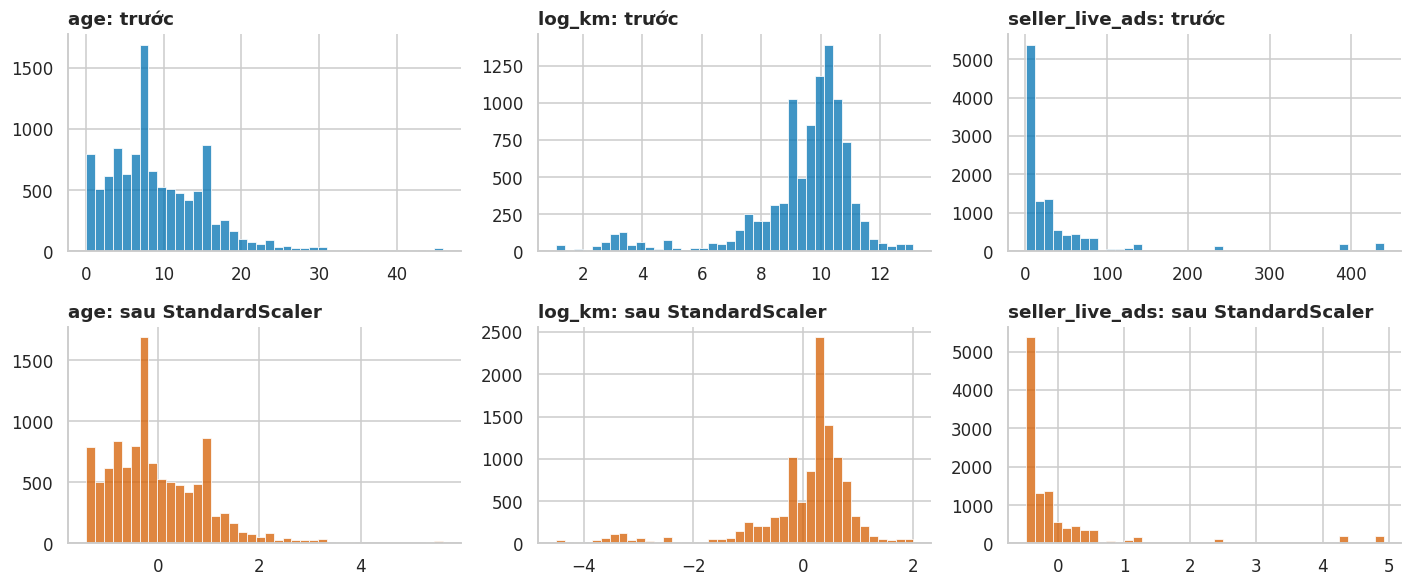

**Hình 8.** Trước chuẩn hóa, ba cột ở ba thang đo khác nhau (`age` mean 9.3, std 6.5, `log_km` mean 9.3, std 2.0, `seller_live_ads` mean 40.0, std 81.3); sau StandardScaler cả ba có mean 0.00, std 1.00. Hình dạng phân phối không đổi (`seller_live_ads` vẫn lệch phải; cột cao ở giữa `log_km` là các ô thiếu đã điền median), nên chuẩn hóa không thay cho việc lấy log.

In [24]:
pre = make_preprocess().fit(X["train"], y["train"])
Xt = pd.DataFrame(pre.transform(X["train"]), columns=pre.get_feature_names_out())
show_cols = ["age", "log_km", "seller_live_ads"]

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for j, col in enumerate(show_cols):
    sns.histplot(X["train"][col].dropna(), bins=40, color=MAIN, ax=axes[0, j])
    sns.histplot(Xt[col], bins=40, color=ACCENT, ax=axes[1, j])
    axes[0, j].set(title=f"{col}: trước", xlabel="", ylabel="")
    axes[1, j].set(title=f"{col}: sau StandardScaler", xlabel="", ylabel="")
before = X["train"][show_cols].agg(["mean", "std"])
after = Xt[show_cols].agg(["mean", "std"])
show_fig(fig, "scaling",
    "Trước chuẩn hóa, ba cột ở ba thang đo khác nhau (" + ", ".join(f"`{c}` mean {before.loc['mean', c]:.1f}, std "
    f"{before.loc['std', c]:.1f}" for c in show_cols) + "); sau StandardScaler cả ba có mean "
    f"{after.loc['mean'].abs().max():.2f}, std {after.loc['std'].mean():.2f}. Hình dạng phân phối không đổi "
    "(`seller_live_ads` vẫn lệch phải; cột cao ở giữa `log_km` là các ô thiếu đã điền median), nên chuẩn hóa không "
    "thay cho việc lấy log.")

### 5.6 Kích thước cuối cùng của ba tập

In [25]:
display(pd.DataFrame({name: {"số tin": len(X[name]), "số feature gốc": X[name].shape[1],
                             "số cột sau tiền xử lý": pre.transform(X[name]).shape[1]} for name in X}).T)

,số tin,số feature gốc,số cột sau tiền xử lý
train,11076,27,167
val,2374,27,167
test,2374,27,167


## 6. Xây dựng mô hình

### 6.1 Thước đo và cách chọn mô hình

- **Thước đo chính: R² trên log10(giá)**, cho biết mô hình giải thích được bao nhiêu phần biến động của giá (1 là hoàn
  hảo, 0 là bằng đoán giá trung bình). Vì học trên thang log, R² này đo sai số theo tỉ lệ chứ không theo số tiền.
- **Thước đo dễ hiểu:** sai số tuyệt đối theo % của giá thật, lấy median trên các tin (`median_APE`), và tỉ lệ tin đoán
  sai không quá 10% (`within_10`). Ví dụ `median_APE = 12%` nghĩa là một nửa số xe được đoán lệch không quá 12% giá
  rao. MAE tính bằng triệu đồng cũng được báo cáo.
- **Cách chọn:** như slide của môn học, mỗi mô hình được chấm bằng **cross-validation 5 fold trên train** (`KFold`,
  xáo trộn, seed 261), báo cáo trung bình và độ lệch giữa các fold, rồi huấn luyện lại trên toàn train và chấm trên
  **validation**. Mô hình có R² validation cao nhất được chọn. Hai mô hình chỉ được coi là khác nhau khi hiệu R² lớn hơn
  độ lệch giữa các fold. Trong notebook này, tập test chỉ được chấm ở mục 7.
- **Mô hình:** các mô hình hồi quy trong slide: hồi quy tuyến tính, kNN, cây quyết định, random forest; thêm gradient
  boosting (phần đọc thêm của slide cây và ensemble) như một mô hình mở rộng.

In [26]:
KF = KFold(n_splits=5, shuffle=True, random_state=SEED)

def scores(y_true, y_pred):
    true, pred = 10 ** y_true, 10 ** y_pred
    ape = np.abs(pred - true) / true
    return {"R2": r2_score(y_true, y_pred), "median_APE_%": 100 * np.median(ape),
            "within_10_%": 100 * np.mean(ape <= 0.10), "MAE_trieu": np.mean(np.abs(pred - true)) / 1e6}

def evaluate(name, model, split="val", cv=True):
    row = {"model": name}
    if cv:
        res = cross_validate(model, X["train"], y["train"], cv=KF, scoring="r2", n_jobs=-1)
        row.update(cv_R2=res["test_score"].mean(), cv_R2_std=res["test_score"].std())
    model.fit(X["train"], y["train"])
    row.update({f"{split}_{k}": v for k, v in scores(y[split], model.predict(X[split])).items()})
    return row, model

### 6.2 Baseline

Hai baseline để biết một mô hình "đủ tốt" là thế nào:

1. **Luôn đoán giá trung bình của train** (`DummyRegressor`), như slide quy trình học máy.
2. **Đoán giá median của dòng xe** trên train (dòng chưa gặp thì lấy median chung). Đây là cách một người mua xe
   thường làm: "SH cũ thì khoảng 60-70 triệu".

In [27]:
def median_by_model(X_fit, y_fit, X_new):
    medians = pd.Series(y_fit, index=X_fit.index).groupby(X_fit["brand_model"]).median()
    return X_new["brand_model"].map(medians).fillna(np.median(y_fit)).to_numpy()

row, dummy = evaluate("Baseline: giá trung bình", DummyRegressor(strategy="mean"))
FITTED = {"Baseline: giá trung bình": dummy}

MEDIAN_BASELINE = "Baseline: median theo dòng xe"
cv = [r2_score(y["train"][te], median_by_model(X["train"].iloc[tr], y["train"][tr], X["train"].iloc[te]))
      for tr, te in KF.split(X["train"])]
val_pred = median_by_model(X["train"], y["train"], X["val"])
rows = [row, {"model": MEDIAN_BASELINE, "cv_R2": np.mean(cv), "cv_R2_std": np.std(cv),
              **{f"val_{k}": v for k, v in scores(y["val"], val_pred).items()}}]
display(pd.DataFrame(rows).round(3))

,model,cv_R2,cv_R2_std,val_R2,val_median_APE_%,val_within_10_%,val_MAE_trieu
0,Baseline: giá trung bình,-0.000,0.000,-0.000,49.629,9.646,15.906
1,Baseline: median theo dòng xe,0.566,0.016,0.579,30.018,18.745,9.864


### 6.3 So sánh các mô hình hồi quy

Bốn mô hình trong slide, cùng dùng bộ tiền xử lý ở mục 5. Cây và random forest không cần chuẩn hóa, nhưng dùng chung
`ColumnTransformer` để mọi mô hình nhận cùng một ma trận đặc trưng.

In [28]:
def pipe(model, encoding="both"):
    return make_pipeline(make_preprocess(encoding), model)

MODELS = {
    "Hồi quy tuyến tính": pipe(LinearRegression()),
    "kNN (k=10)": pipe(KNeighborsRegressor(n_neighbors=10, weights="distance")),
    "Cây quyết định (sâu 12)": pipe(DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=SEED)),
    "Random forest": pipe(RandomForestRegressor(n_estimators=300, max_features=0.5, n_jobs=-1, random_state=SEED)),
}
for name, model in MODELS.items():
    row, FITTED[name] = evaluate(name, model)
    rows.append(row)
val_res = pd.DataFrame(rows)
display(val_res.round(3))

,model,cv_R2,cv_R2_std,val_R2,val_median_APE_%,val_within_10_%,val_MAE_trieu
0,Baseline: giá trung bình,-0.000,0.000,-0.000,49.629,9.646,15.906
1,Baseline: median theo dòng xe,0.566,0.016,0.579,30.018,18.745,9.864
2,Hồi quy tuyến tính,0.753,0.012,0.749,21.320,25.990,7.377
3,kNN (k=10),0.771,0.011,0.768,19.671,28.265,6.931
4,Cây quyết định (sâu 12),0.783,0.014,0.788,15.395,35.341,6.049
5,Random forest,0.859,0.011,0.858,12.133,43.471,4.912


### 6.4 Ảnh hưởng của tham số: độ sâu của cây và số láng giềng

`max_depth` của cây và `k` của kNN là hyperparameter: không học từ dữ liệu mà do người làm chọn. Hình dưới thay đổi
từng tham số, chấm R² trên train và trên validation.

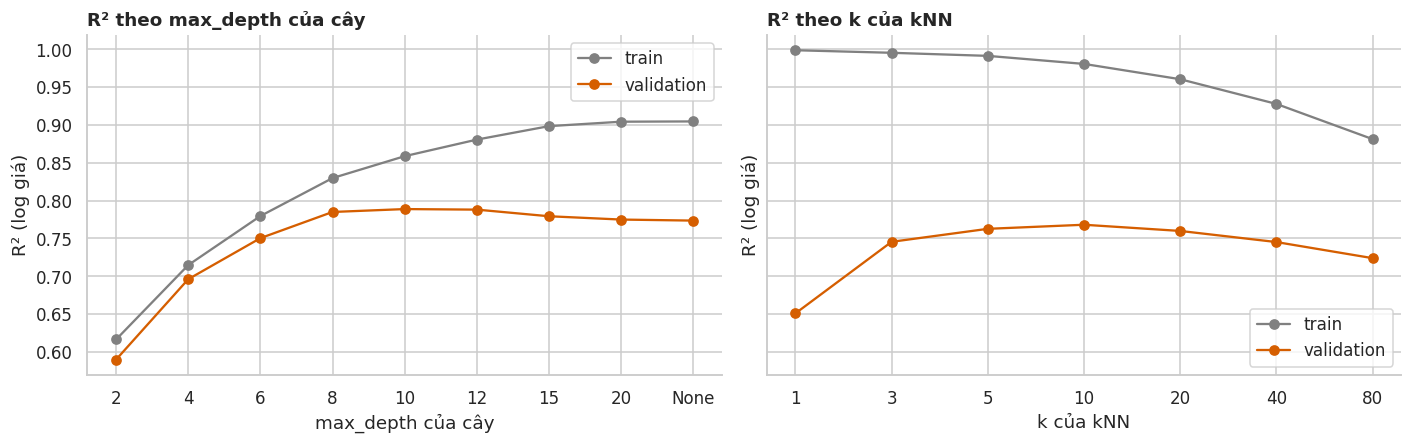

**Hình 9.** Cây càng sâu, R² train càng tăng (0.905 khi không giới hạn), nhưng R² validation cao nhất là 0.789 ở max_depth=10 và chỉ còn 0.774 khi không giới hạn: cây quá sâu bị overfitting. kNN có R² train gần 1 vì mỗi điểm train là láng giềng của chính nó; R² validation cao nhất 0.768 ở k=10, vẫn kém random forest nên không tinh chỉnh thêm.

In [29]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, None]
ks = [1, 3, 5, 10, 20, 40, 80]
def sweep(make, values):
    out = []
    for v in values:
        m = make(v).fit(X["train"], y["train"])
        out.append({"value": str(v), "train": r2_score(y["train"], m.predict(X["train"])),
                    "val": r2_score(y["val"], m.predict(X["val"]))})
    return pd.DataFrame(out)

tree_sweep = sweep(lambda d: pipe(DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=SEED)), depths)
knn_sweep = sweep(lambda k: pipe(KNeighborsRegressor(n_neighbors=k, weights="distance")), ks)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, sw, label in [(axes[0], tree_sweep, "max_depth của cây"), (axes[1], knn_sweep, "k của kNN")]:
    xs = sw["value"]
    ax.plot(xs, sw["train"], marker="o", color="grey", label="train")
    ax.plot(xs, sw["val"], marker="o", color=ACCENT, label="validation")
    ax.set(xlabel=label, ylabel="R² (log giá)", title=f"R² theo {label}")
    ax.legend()
best_d = tree_sweep.loc[tree_sweep["val"].idxmax()]
best_k = knn_sweep.loc[knn_sweep["val"].idxmax()]
deep = tree_sweep.iloc[-1]
show_fig(fig, "hyperparameters",
    f"Cây càng sâu, R² train càng tăng ({deep['train']:.3f} khi không giới hạn), nhưng R² validation cao nhất là "
    f"{best_d['val']:.3f} ở max_depth={best_d['value']} và chỉ còn {deep['val']:.3f} khi không giới hạn: cây quá sâu bị "
    f"overfitting. kNN có R² train gần 1 vì mỗi điểm train là láng giềng của chính nó; R² validation cao nhất "
    f"{best_k['val']:.3f} ở k={int(best_k['value'])}, vẫn kém random forest nên không tinh chỉnh thêm.")

### 6.5 Mở rộng: gradient boosting

Random forest lấy trung bình nhiều cây học độc lập. Gradient boosting (phần đọc thêm của slide cây và ensemble) xây cây
lần lượt, cây sau học phần sai của các cây trước. `HistGradientBoostingRegressor` là bản nhanh của scikit-learn,
dùng được với hơn 10 000 dòng. Thử ba cấu hình và chọn theo validation.

In [30]:
hgb_rows = []
for lr, leaves, iters in [(0.05, 31, 800), (0.03, 63, 1500), (0.1, 15, 400)]:
    name = f"Gradient boosting (lr={lr}, leaves={leaves}, iter={iters})"
    m = pipe(HistGradientBoostingRegressor(learning_rate=lr, max_leaf_nodes=leaves, max_iter=iters,
                                           l2_regularization=1.0, random_state=SEED))
    hgb_rows.append((evaluate(name, m, cv=False)[0], m))
display(pd.DataFrame([r for r, _ in hgb_rows]).round(3))

best_row, best_hgb = max(hgb_rows, key=lambda t: t[0]["val_R2"])
row, FITTED["Gradient boosting"] = evaluate("Gradient boosting", best_hgb)
val_res = pd.concat([val_res, pd.DataFrame([row])], ignore_index=True)
print("Cấu hình được chọn:", best_row["model"])

,model,val_R2,val_median_APE_%,val_within_10_%,val_MAE_trieu
0,"Gradient boosting (lr=0.05, leaves=31, iter=800)",0.852,13.826,38.922,5.305
1,"Gradient boosting (lr=0.03, leaves=63, iter=1500)",0.856,13.171,41.281,5.157
2,"Gradient boosting (lr=0.1, leaves=15, iter=400)",0.851,13.956,37.616,5.308


Cấu hình được chọn: Gradient boosting (lr=0.03, leaves=63, iter=1500)


### 6.6 Mã hóa dòng xe: one-hot, target encoding hay cả hai?

Đây là quyết định tiền xử lý quan trọng nhất ở mục 4.2. Để kiểm tra, giữ nguyên mọi thứ khác và chỉ đổi cách mã hóa
bốn cột nhiều mức (`brand`, `brand_model`, `model_cc`, `district`):

- **one-hot**: mỗi mức có từ 5 tin một cột, các mức hiếm hơn gộp chung một cột "hiếm";
- **target encoding**: mỗi cột thành một con số (giá trung bình đã làm mượt);
- **cả hai**: cách đang dùng ở mục 6.3.

,model,mã hóa,số cột,R2,median_APE_%,within_10_%,MAE_trieu
0,Hồi quy tuyến tính,one-hot,368,0.750,20.095,27.464,7.105
1,Hồi quy tuyến tính,target encoding,50,0.744,22.987,24.136,7.567
2,Hồi quy tuyến tính,cả hai,167,0.749,21.320,25.990,7.377
3,Random forest,one-hot,368,0.848,12.340,42.586,4.992
4,Random forest,target encoding,50,0.856,12.492,42.881,4.980
5,Random forest,cả hai,167,0.858,12.133,43.471,4.912


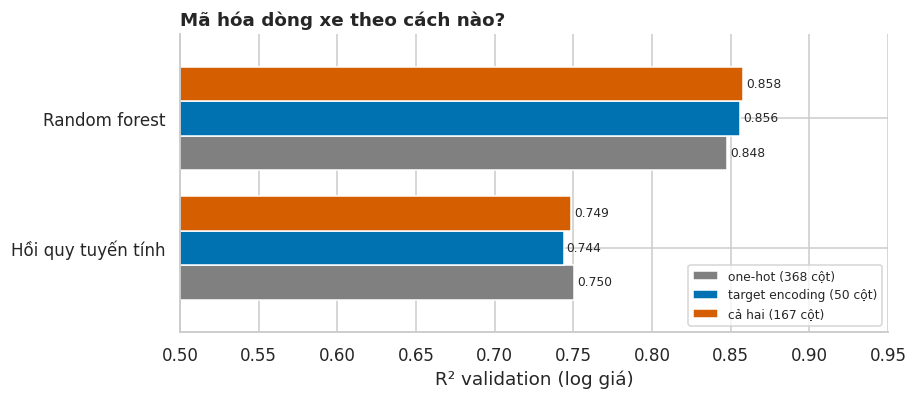

**Hình 10.** Với random forest, target encoding (0.856) tốt hơn one-hot (0.848) mà chỉ cần 50 cột thay vì 368; dùng cả hai cao nhất (0.858, sai số 12.1%). Với hồi quy tuyến tính, ba cách gần như bằng nhau (0.744-0.750).

In [31]:
enc_rows = []
ENC_LABEL = {"onehot": "one-hot", "target": "target encoding", "both": "cả hai"}
for name, model in [("Hồi quy tuyến tính", LinearRegression()),
                    ("Random forest", RandomForestRegressor(n_estimators=300, max_features=0.5, n_jobs=-1, random_state=SEED))]:
    for enc in ENC_LABEL:
        p = pipe(model, enc).fit(X["train"], y["train"])
        n_feat = p[0].transform(X["val"].head(1)).shape[1]
        enc_rows.append({"model": name, "mã hóa": ENC_LABEL[enc], "số cột": n_feat, **scores(y["val"], p.predict(X["val"]))})
enc_res = pd.DataFrame(enc_rows)
display(enc_res.round(3))

order_enc = list(ENC_LABEL.values())
piv = enc_res.pivot(index="model", columns="mã hóa", values="R2")[order_enc]
ape = enc_res.pivot(index="model", columns="mã hóa", values="median_APE_%")[order_enc]
ncol = enc_res.pivot(index="model", columns="mã hóa", values="số cột").iloc[0]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
piv.plot.barh(ax=ax, color=["grey", MAIN, ACCENT], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set(xlim=(0.5, 0.95), xlabel="R² validation (log giá)", ylabel="", title="Mã hóa dòng xe theo cách nào?")
ax.legend([f"{e} ({ncol[e]} cột)" for e in order_enc], loc="lower right", fontsize=8)
lin, rf_ = piv.loc["Hồi quy tuyến tính"], piv.loc["Random forest"]
show_fig(fig, "encoding",
    f"Với random forest, target encoding ({rf_['target encoding']:.3f}) tốt hơn one-hot ({rf_['one-hot']:.3f}) mà chỉ "
    f"cần {ncol['target encoding']} cột thay vì {ncol['one-hot']}; dùng cả hai cao nhất ({rf_['cả hai']:.3f}, sai số "
    f"{ape.loc['Random forest', 'cả hai']:.1f}%). Với hồi quy tuyến tính, ba cách gần như bằng nhau "
    f"({lin.min():.3f}-{lin.max():.3f}).")

- **Nhận xét:**
  - One-hot phải gộp các mức ít tin (dòng xe + dung tích hiếm, quận ít tin) vào một cột "hiếm", còn target encoding giữ được mức giá riêng của từng mức, nên tốt hơn với random forest.
  - Hiệu R² giữa "cả hai" và target encoding (0.002) nhỏ hơn độ lệch giữa các fold của random forest (0.011), nên hai cách coi như ngang nhau.
  - Với hồi quy tuyến tính, one-hot nhỉnh nhất vì mỗi dòng xe có một hệ số riêng.
- **Quyết định:** giữ cách "cả hai" cho mọi mô hình, vì tốt nhất với mô hình mạnh nhất và chỉ kém one-hot 0.001 với hồi quy tuyến tính.

### 6.7 So sánh tổng hợp và mô hình cuối cùng

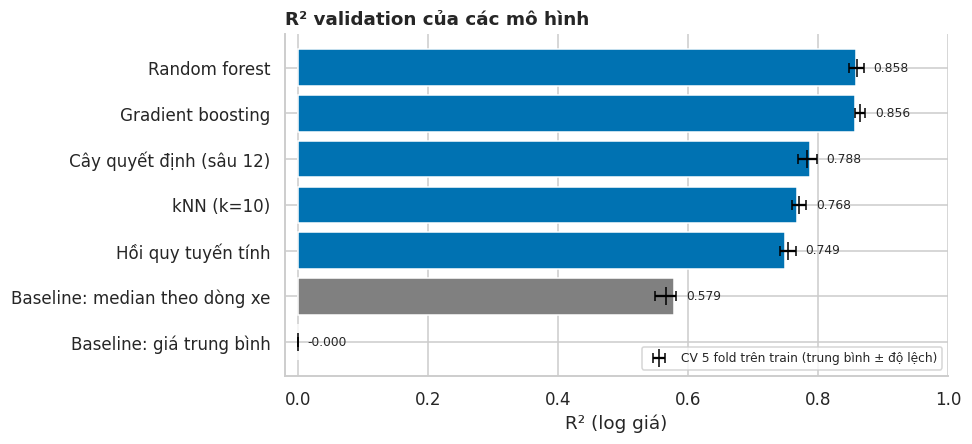

**Hình 11.** **Random forest** có R² validation cao nhất (0.858), tiếp theo là Gradient boosting (0.856); hiệu 0.002 nhỏ hơn độ lệch giữa các fold (0.011 và 0.008). So với baseline median theo dòng xe, sai số % median giảm từ 30.0% xuống 12.1%.

Mô hình cuối cùng: Random forest


In [32]:
plot_res = val_res.sort_values("val_R2")
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["grey" if n.startswith("Baseline") else MAIN for n in plot_res["model"]]
ax.barh(plot_res["model"], plot_res["val_R2"], color=colors)
ax.errorbar(plot_res["cv_R2"], plot_res["model"], xerr=plot_res["cv_R2_std"], fmt="|", color="black", ms=12,
            capsize=3, label="CV 5 fold trên train (trung bình ± độ lệch)")
for yi, r in enumerate(plot_res.itertuples()):
    ax.text(max(r.val_R2, r.cv_R2 + r.cv_R2_std, 0) + 0.015, yi, f"{r.val_R2:.3f}", va="center", fontsize=8)
ax.set(xlim=(-0.02, 1), xlabel="R² (log giá)", ylabel="", title="R² validation của các mô hình")
ax.legend(loc="lower right", fontsize=8)

ranked = val_res.sort_values("val_R2", ascending=False).reset_index(drop=True)
FINAL_NAME = ranked.loc[0, "model"]
first, second = ranked.iloc[0], ranked.iloc[1]
base = val_res.set_index("model").loc["Baseline: median theo dòng xe"]
gap = first["val_R2"] - second["val_R2"]
show_fig(fig, "model_comparison",
    f"**{FINAL_NAME}** có R² validation cao nhất ({first['val_R2']:.3f}), tiếp theo là {second['model']} "
    f"({second['val_R2']:.3f}); hiệu {gap:.3f} "
    f"{'lớn hơn' if gap > max(first['cv_R2_std'], second['cv_R2_std']) else 'nhỏ hơn'} độ lệch giữa các fold "
    f"({first['cv_R2_std']:.3f} và {second['cv_R2_std']:.3f}). So với baseline median theo dòng xe, sai số % median "
    f"giảm từ {base['val_median_APE_%']:.1f}% xuống {first['val_median_APE_%']:.1f}%.")
print("Mô hình cuối cùng:", FINAL_NAME)

## 7. Đánh giá trên tập test

### 7.1 Kết quả trên test

Mọi mô hình đã huấn luyện trên train ở mục 6 được chấm trên tập test. Mô hình cuối cùng là mô hình có R² validation
cao nhất ở mục 6.7.

In [33]:
TEST_PRED = {name: m.predict(X["test"]) for name, m in FITTED.items()}
TEST_PRED[MEDIAN_BASELINE] = median_by_model(X["train"], y["train"], X["test"])
TEST_PRED = {name: TEST_PRED[name] for name in val_res["model"]}
test_res = pd.DataFrame([{"model": name, "final": name == FINAL_NAME,
                          "val_R2": val_res.set_index("model").loc[name, "val_R2"],
                          **{f"test_{k}": v for k, v in scores(y["test"], pred).items()}}
                         for name, pred in TEST_PRED.items()])
display(test_res.round(3))
final_test = test_res.set_index("model").loc[FINAL_NAME]

,model,final,val_R2,test_R2,test_median_APE_%,test_within_10_%,test_MAE_trieu
0,Baseline: giá trung bình,False,-0.000,-0.000,49.629,9.815,15.747
1,Baseline: median theo dòng xe,False,0.579,0.574,28.302,19.082,9.570
2,Hồi quy tuyến tính,False,0.749,0.738,20.856,26.369,7.435
3,kNN (k=10),False,0.768,0.781,19.299,28.180,6.876
4,Cây quyết định (sâu 12),False,0.788,0.778,15.013,36.352,6.039
5,Random forest,True,0.858,0.851,11.574,45.409,4.717
6,Gradient boosting,False,0.856,0.853,12.661,42.165,4.982


- **Nhận xét:**
  - Mô hình cuối cùng (random forest) đạt R² 0.851 trên test, gần với validation (0.858) và CV (0.859).
  - Gradient boosting đạt R² test 0.853 nhưng sai số % median cao hơn (12.7% so với 11.6%). Hai mô hình chênh nhau ít hơn độ lệch giữa các fold nên coi như ngang nhau; random forest được giữ theo quy tắc chọn bằng validation.
  - So với baseline median theo dòng xe, sai số % median giảm từ 28.3% xuống 11.6%, tức còn khoảng 40%.

### 7.2 Dự đoán so với giá thật

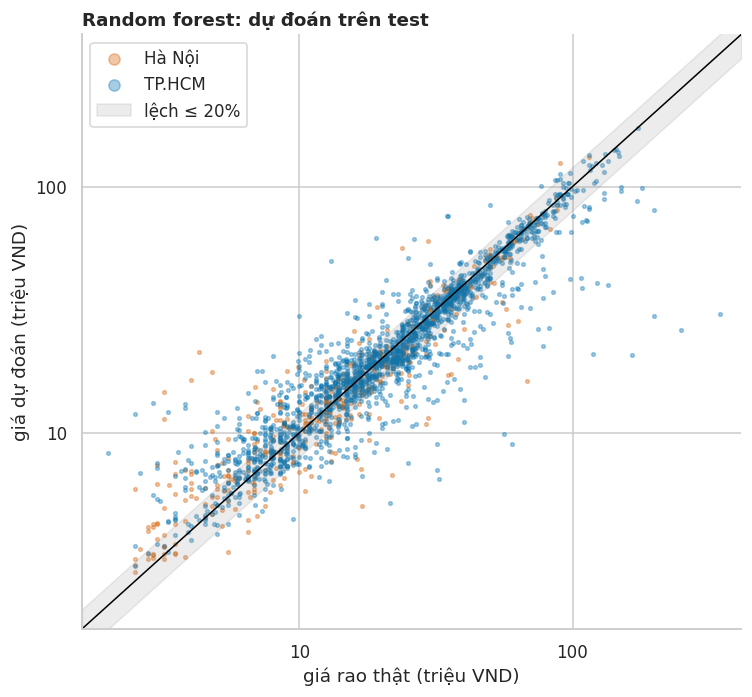

**Hình 12.** Trên 2 374 tin test, 68.7% tin được đoán lệch không quá 20% (dải xám), ở mọi mức giá. Chỉ 217 tin (9.1%) lệch quá 50%; 71% trong số đó là đoán **cao hơn** giá rao và 45% thuộc 20% tin rẻ nhất.

In [34]:
final_model = FITTED[FINAL_NAME]
res = FEAT["test"][["subject", "city", "brand", "model", "reg_year", "mileage_km", "seller_is_shop", TARGET]].copy()
res["pred"] = 10 ** TEST_PRED[FINAL_NAME]
res["ape"] = (res["pred"] - res[TARGET]).abs() / res[TARGET]

fig, ax = plt.subplots(figsize=(7, 6.5))
for city, g in res.groupby("city"):
    ax.scatter(g[TARGET], g["pred"], s=6, alpha=0.35, color=CITY_COLORS[city], label=city)
lims = [res[[TARGET, "pred"]].min().min() * 0.8, res[[TARGET, "pred"]].max().max() * 1.2]
ax.plot(lims, lims, color="black", lw=1)
ax.fill_between(lims, [v * 0.8 for v in lims], [v * 1.2 for v in lims], color="grey", alpha=0.15, label="lệch ≤ 20%")
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="giá rao thật (triệu VND)",
       ylabel="giá dự đoán (triệu VND)", title=f"{FINAL_NAME}: dự đoán trên test")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(mticker.FuncFormatter(trieu))
    axis.set_minor_formatter(mticker.NullFormatter())
ax.legend(markerscale=3)
within20 = (res["ape"] <= 0.2).mean()
far = res[res["ape"] > 0.5]
show_fig(fig, "pred_vs_true",
    f"Trên {num(len(res))} tin test, {pct(within20)} tin được đoán lệch không quá 20% (dải xám), ở mọi mức giá. Chỉ "
    f"{len(far)} tin ({pct(len(far) / len(res))}) lệch quá 50%; {pct((far['pred'] > far[TARGET]).mean(), 0)} trong số "
    f"đó là đoán **cao hơn** giá rao và {pct((far[TARGET] < res[TARGET].quantile(0.2)).mean(), 0)} thuộc 20% tin rẻ nhất.")

### 7.3 Mô hình dựa vào những feature nào?

Độ quan trọng của feature trong random forest (`feature_importances_`) đo mức giảm sai số trung bình mà mỗi feature
mang lại khi được dùng để tách nút. Các cột one-hot và cột cờ "bị thiếu" của cùng một feature gốc được cộng lại.

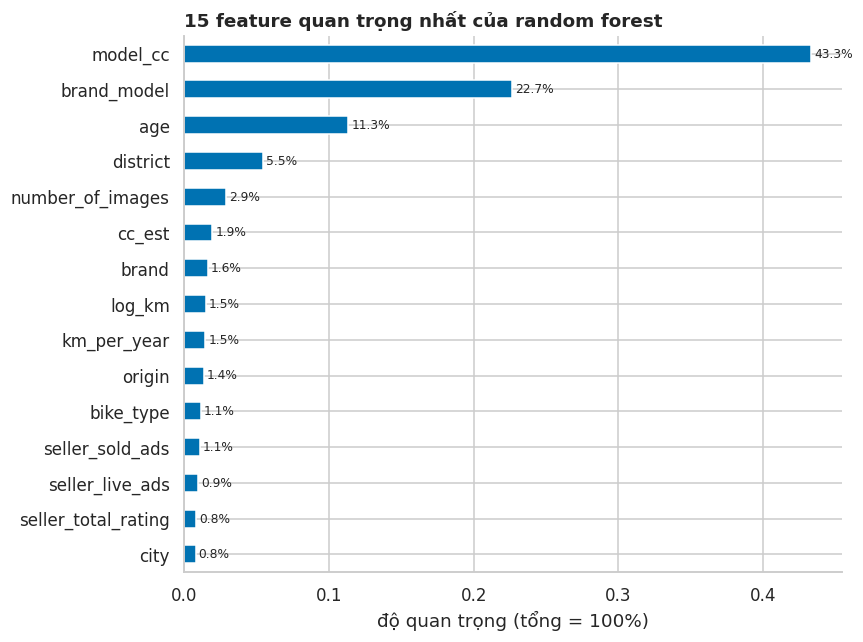

**Hình 13.** Năm feature quan trọng nhất: `model_cc` (43.3%), `brand_model` (22.7%), `age` (11.3%), `district` (5.5%), `number_of_images` (2.9%). Gộp theo nhóm: "đây là xe gì" (dòng xe, hãng, dung tích, loại xe) chiếm 70.7%, đời xe và số km 14.3%, nơi bán và người bán 9.9%, khớp với EDA ở mục 4.2 và 4.3.

In [35]:
rf = FITTED["Random forest"]
names = rf[0].get_feature_names_out()
origin_of = {n: next(c for c in sorted(FEATURES, key=len, reverse=True) if n.removeprefix("missingindicator_").startswith(c))
             for n in names}
imp = pd.Series(rf[-1].feature_importances_, index=names).groupby(origin_of).sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
imp.tail(15).plot.barh(ax=ax, color=MAIN)
ax.bar_label(ax.containers[0], labels=[pct(v) for v in imp.tail(15)], fontsize=8, padding=2)
ax.set(xlabel="độ quan trọng (tổng = 100%)", ylabel="", title="15 feature quan trọng nhất của random forest")
ranked_imp = imp.sort_values(ascending=False)
vehicle = ranked_imp[["model_cc", "brand_model", "brand", "cc_est", "bike_type"]].sum()
usage = ranked_imp[["age", "log_km", "km_per_year"]].sum()
place_seller = ranked_imp[["city", "district", "seller_is_shop", "seller_live_ads", "seller_sold_ads",
                           "seller_avg_rating", "seller_total_rating"]].sum()
show_fig(fig, "feature_importance",
    "Năm feature quan trọng nhất: " + ", ".join(f"`{k}` ({pct(v)})" for k, v in ranked_imp.head(5).items())
    + f". Gộp theo nhóm: \"đây là xe gì\" (dòng xe, hãng, dung tích, loại xe) chiếm {pct(vehicle)}, đời xe và số km "
    f"{pct(usage)}, nơi bán và người bán {pct(place_seller)}, khớp với EDA ở mục 4.2 và 4.3.")

### 7.4 Mô hình sai ở đâu?


Sai số % median theo 5 khoảng giá bằng nhau và theo nơi bán / người bán. Cột `pred/true` là median của tỉ số giá dự
đoán / giá thật: lớn hơn 1 nghĩa là mô hình thường đoán cao hơn giá rao.

In [36]:
res["price_band"] = pd.qcut(res[TARGET] / 1e6, 5).map(lambda b: f"{b.left:.0f}-{b.right:.0f} triệu")
res["seller"] = res["city"] + ", " + res["seller_is_shop"].map({1: "cửa hàng", 0: "cá nhân"})
res["ratio"] = res["pred"] / res[TARGET]

def error_table(by):
    return res.groupby(by, observed=True).agg(n=("ape", "size"), median_APE_pct=("ape", lambda s: 100 * s.median()),
                                              pred_over_true=("ratio", "median")).round(2)

display(error_table("price_band"))
display(error_table("seller"))

,n,median_APE_pct,pred_over_true
price_band,,,
2-9 triệu,483,19.71,1.16
9-16 triệu,478,14.56,1.05
16-24 triệu,463,10.16,0.97
24-38 triệu,475,8.97,0.96
38-346 triệu,475,7.61,0.96


,n,median_APE_pct,pred_over_true
seller,,,
"Hà Nội, cá nhân",103,17.21,0.97
"Hà Nội, cửa hàng",346,12.42,1.02
"TP.HCM, cá nhân",527,15.58,1.00
"TP.HCM, cửa hàng",1398,9.91,0.99


- **Nhận xét:**
  - Sai số giảm dần theo mức giá: 19.7% ở 20% tin rẻ nhất (dưới 9 triệu), 7.6% ở 20% tin đắt nhất. Ở nhóm rẻ nhất, mô hình thường đoán cao hơn giá rao (tỉ số 1.16): với xe vài triệu, chênh một hai triệu đã là nhiều phần trăm.
  - Nhóm khó đoán nhất là người bán cá nhân ở Hà Nội (17.2%). Tỉ số dự đoán / giá thật của cả bốn nhóm đều trong khoảng 0.97-1.02, nên mô hình không đoán lệch hẳn về một phía ở nhóm nào.

Năm tin bị đoán sai nhiều nhất trên test:

In [37]:
with pd.option_context("display.max_colwidth", 55):
    worst = res.sort_values("ape", ascending=False).head(5)
    display(worst[["subject", "city", "model", "reg_year", "mileage_km", TARGET, "pred", "ape"]]
            .assign(**{TARGET: worst[TARGET] / 1e6, "pred": worst["pred"] / 1e6}).round(2))

,subject,city,model,reg_year,mileage_km,price_vnd,pred,ape
14096,Honda Dream Đỏ đen,Hà Nội,Dream,2004,99999.0,4.3,21.20,3.93
9498,Honda Wave xe máy số màu Xanh,TP.HCM,Wave,2019,332.0,2.5,11.93,3.77
10196,cần bán chiếc Future,TP.HCM,Dream,2012,10000.0,2.9,13.26,3.57
13885,Piaggio Liberty Xám Xe tay ga,Hà Nội,Liberty,2022,10000.0,3.2,14.59,3.56
1296,Honda Cub Xanh rêu Nhật Bản,TP.HCM,Cub,1981,20000.0,2.0,8.29,3.14


### 7.5 Lưu bảng kết quả

Bảng test được ghi vào `results/tabular_metrics.csv` và `results/tabular_metrics.md`; báo cáo PDF và trang web lấy số
liệu từ các file này.

In [38]:
test_res.round(4).to_csv(RESULTS_DIR / "tabular_metrics.csv", index=False)

def md_table(d):
    cols = list(d.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    return "\n".join(lines + ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)])

enc_md = enc_res[["model", "mã hóa", "số cột", "R2", "median_APE_%"]].round(4)
(RESULTS_DIR / "tabular_metrics.md").write_text("\n\n".join([
    "# Tabular (Chợ Tốt xe máy cũ): kết quả trên tập test",
    f"Sinh ra bởi `tabular.ipynb`. Tập test: {len(X['test']):,} tin. `final = True` là mô hình chọn theo R² validation. "
    "R2 tính trên log10(giá).",
    "## Các mô hình", md_table(test_res.round(4)),
    "## Thí nghiệm: one-hot so với target encoding (validation)", md_table(enc_md),
]), encoding="utf-8")
print("Đã lưu results/tabular_metrics.csv và results/tabular_metrics.md")

Đã lưu results/tabular_metrics.csv và results/tabular_metrics.md


## 8. Dự đoán giá xe mới

### 8.1 Hàm dự đoán từ thông tin một chiếc xe

Hàm nhận thông tin như khi đăng một tin trên Chợ Tốt, đi qua đúng các bước của mục 5.2 và pipeline của mô hình cuối
cùng. Cột nào không khai thì để trống, pipeline tự điền như với dữ liệu thật. Xe thuộc dòng ngoài phạm vi (mục 3.7) bị
từ chối thay vì trả về một con số không đáng tin.

In [39]:
RAW_COLS = [c for c in clean.columns if c != TARGET]

def predict_price(estimator=final_model, **info):
    key = f"{info.get('brand')} | {info.get('model')}"
    if key not in POPULAR:
        raise ValueError(f"{key} không thuộc {len(POPULAR)} dòng xe phổ biến (mục 3.7), mô hình không dự đoán.")
    row = pd.DataFrame([info]).reindex(columns=RAW_COLS)
    row["posted_at"] = pd.to_datetime(info.get("posted_at", "2026-11-16"))
    row["subject"] = row["subject"].fillna("")
    row["seller_is_shop"] = row["seller_is_shop"].fillna(False).astype(bool)
    text_cols = LOW_CAT + ["brand", "model", "district"]
    row[text_cols] = row[text_cols].astype(object)
    feats = add_features(row)[FEATURES]
    return float(10 ** estimator.predict(feats)[0])

### 8.2 Thử với vài chiếc xe

Cùng một chiếc Honda Vision, thay đổi lần lượt đời xe, số km và nơi bán để xem mô hình phản ứng thế nào.

In [40]:
base_bike = dict(subject="Honda Vision 110cc smartkey", brand="Honda", model="Vision", bike_type="Tay ga",
                 origin="Việt Nam", capacity="100 - 175 cc", condition="Đã sử dụng", reg_year=2021, mileage_km=20000,
                 city="TP.HCM", district="Quận Gò Vấp", seller_is_shop=False, number_of_images=6)
cases = {
    "Vision 2021, 20 000 km, cá nhân, Gò Vấp": {},
    "đời 2017 thay vì 2021": dict(reg_year=2017),
    "đi 60 000 km thay vì 20 000 km": dict(mileage_km=60000),
    "bán ở Hà Nội (Cầu Giấy), cá nhân": dict(city="Hà Nội", district="Quận Cầu Giấy"),
    "bán ở Hà Nội (Nam Từ Liêm), cửa hàng": dict(city="Hà Nội", district="Quận Nam Từ Liêm", seller_is_shop=True),
    "Honda SH 150i 2021 thay vì Vision": dict(model="SH", subject="Honda SH 150i ABS", capacity="100 - 175 cc"),
}
pred_cases = pd.Series({k: predict_price(**{**base_bike, **v}) / 1e6 for k, v in cases.items()}, name="giá dự đoán (triệu)")
pred_cases.round(1).to_frame()

,giá dự đoán (triệu)
"Vision 2021, 20 000 km, cá nhân, Gò Vấp",24.5
đời 2017 thay vì 2021,17.6
đi 60 000 km thay vì 20 000 km,21.7
"bán ở Hà Nội (Cầu Giấy), cá nhân",22.2
"bán ở Hà Nội (Nam Từ Liêm), cửa hàng",14.4
Honda SH 150i 2021 thay vì Vision,73.8


- **Nhận xét:**
  - Cùng một chiếc Vision 2021 đi 20 000 km bán ở Gò Vấp, mô hình đoán 24.5 triệu.
  - Đổi sang đời 2017 thì giá còn 17.6 triệu (giảm 28%, tức khoảng 8% mỗi năm, gần với mức 7% mỗi năm của Vision ở Hình 6).
  - Đi 60 000 km thay vì 20 000 km thì còn 21.7 triệu (giảm 11%).
  - Bán ở Hà Nội thì giá thấp hơn, và thấp hẳn khi người bán là cửa hàng ở Nam Từ Liêm (14.4 triệu, khoảng 0.6 lần giá ở TP.HCM). Mô hình đã học lại đúng hiện tượng ở mục 4.4.
  - Đổi dòng xe sang SH 150i thì giá lên 73.8 triệu: dòng xe vẫn là yếu tố quyết định.

## 9. Kết luận

### 9.1 Tóm tắt kết quả trên tập test

Phạm vi: 65 dòng xe phổ biến, chiếm 82.8% số tin sau khi làm sạch (mục 3.7).

| Mô hình | R² (log giá) | Sai số % median | Tin lệch ≤ 10% | MAE (triệu) |
|---|---:|---:|---:|---:|
| Baseline: giá trung bình | 0.000 | 49.6% | 9.8% | 15.75 |
| Baseline: median theo dòng xe | 0.574 | 28.3% | 19.1% | 9.57 |
| Hồi quy tuyến tính | 0.738 | 20.9% | 26.4% | 7.44 |
| kNN (k=10) | 0.781 | 19.3% | 28.2% | 6.88 |
| Cây quyết định (sâu 12) | 0.778 | 15.0% | 36.4% | 6.04 |
| **Random forest (mô hình cuối cùng)** | **0.851** | **11.6%** | **45.4%** | **4.72** |
| Gradient boosting | 0.853 | 12.7% | 42.2% | 4.98 |

Mô hình cuối cùng giải thích 85% biến động của log(giá). Một nửa số xe được đoán lệch không quá 11.6% giá rao, so với
28.3% nếu chỉ tra giá trung vị của dòng xe. Gradient boosting đạt kết quả tương đương.

### 9.2 Các câu hỏi đã được trả lời

| # | Câu hỏi | Trả lời |
|---|---|---|
| 1 | Dữ liệu tự thu thập có những lỗi gì? | 74 tin giá rác hoặc tin cần mua, 517 tin đăng lại (2.6%), 2 093 tin xe đã dùng khai số km ảo (10.8%, riêng 12 345 km xuất hiện 358 lần), 3 cột hằng, tọa độ chỉ ở mức phường (mục 3). |
| 2 | Xe mất giá bao nhiêu theo đời và số km? | Khoảng 5-9% mỗi năm đời xe với 4 dòng phổ biến nhất. Xe đi trên 80 000 km còn 61-88% giá của xe đi dưới 5 000 km (mục 4.3). |
| 3 | Cùng dòng, cùng đời, Hà Nội có rẻ hơn TP.HCM không? | Người bán cá nhân ở Hà Nội rao bằng 0.90 lần giá TP.HCM, cửa hàng chỉ 0.62 lần, thấp nhất ở Nam Từ Liêm (0.50 lần). Chênh lệch chủ yếu đến từ một nhóm cửa hàng, không phải toàn thị trường (mục 4.4). |
| 4 | Mã hóa dòng xe thế nào tốt nhất? | Với random forest: one-hot 0.848, target encoding 0.856, cả hai 0.858 (R² validation). Với hồi quy tuyến tính, ba cách gần như bằng nhau (mục 6.6). |
| 5 | Mô hình nào tốt nhất? | Random forest và gradient boosting ngang nhau (hiệu R² validation 0.002, nhỏ hơn độ lệch giữa các fold) và vượt xa hồi quy tuyến tính, kNN, cây đơn (mục 6.7, 7.1). |
| 6 | Mô hình dựa vào đâu, sai ở đâu? | Thông tin "đây là xe gì" chiếm 70.7% độ quan trọng, đời xe và số km 14.3%. Sai số giảm từ 19.7% ở nhóm xe dưới 9 triệu xuống 7.6% ở nhóm xe đắt nhất (mục 7.3, 7.4). |

### 9.3 Hạn chế

* **Giá rao không phải giá bán.** Nhãn là giá người bán tự đặt. Nhóm cửa hàng rao giá rất thấp ở Hà Nội (mục 4.4) cho
  thấy một phần giá rao có thể không phải giá giao dịch thật, và dữ liệu hiện có không kiểm chứng được điều này.
* **Một lần thu thập.** Dữ liệu là các tin đang hiển thị ngày 16/11/2026. Xe bán nhanh (thường là xe giá tốt) có thể đã
  bị gỡ trước đó, nên dữ liệu thiếu chúng. Mô hình cũng chưa biết giá thay đổi theo thời gian.
* **Thiếu thông tin tình trạng xe.** Trầy xước, máy móc, giấy tờ nằm trong ảnh và phần mô tả mà nhóm không thu thập
  (để bảo vệ thông tin cá nhân). Đây là phần lớn sai số còn lại.
* **Số km do người bán tự khai** và không kiểm chứng được; 11% tin bị coi là thiếu số km.
* **Chỉ áp dụng cho 65 dòng xe phổ biến.** Các dòng hiếm (11.6% số tin) và nhóm `Dòng khác` (5.6%) nằm ngoài phạm vi,
  vì quá ít tin để học và đánh giá. Muốn dự đoán chúng cần thu thập thêm dữ liệu.
* **Điểm test có thể hơi lạc quan.** Trước khi viết bản notebook này, nhóm đã thử vài phạm vi dữ liệu (toàn bộ dòng xe,
  dòng xe phổ biến với các ngưỡng khác nhau) và vài cách mã hóa, và có xem điểm test của các lần thử đó. Quyết định
  giới hạn vào 65 dòng xe phổ biến được đưa ra sau các lần thử này, nên tập test không còn hoàn toàn "chưa thấy". Mức
  lạc quan có lẽ nhỏ, vì R² validation (0.858) và CV trên train (0.859) gần với R² test (0.851).
* **Luật bỏ giá thấp vô lý dùng nhãn.** Mục 5.1 bỏ 5 tin ở validation và test dựa trên chính giá rao của chúng, nên
  điểm chỉ áp dụng cho các tin có giá hợp lý; khi dùng thật, một tin đặt cọc vẫn sẽ bị đoán theo giá của cả chiếc xe.
* **Tinh chỉnh ít.** Mỗi mô hình chỉ thử vài giá trị tham số, chọn theo validation.

### 9.4 Hướng mở rộng

* Đưa phần mô tả tin vào mô hình bằng TF-IDF hoặc embedding tiếng Việt (như bài Text của nhóm), và ảnh xe bằng mô hình
  pretrained (như bài Image), để có thông tin về tình trạng xe.
* Thu thập nhiều đợt để theo dõi giá theo thời gian và biết tin nào được gỡ sớm (nhiều khả năng đã bán).
* Dự đoán một khoảng giá (ví dụ từ phân vị 10% đến 90%) thay vì một con số, phù hợp hơn với người mua.
* Tinh chỉnh tham số bằng `GridSearchCV` trên cross-validation, và mở rộng sang các tỉnh thành khác.